In [1]:
from cnmodel import populations
from cnmodel.util import sound, random_seed
from cnmodel.protocols import Protocol
from collections import OrderedDict
import os, sys, time
import pickle
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from neuron import h
import multiprocessing as mp
from scipy.signal import savgol_filter
import yaml
import seaborn as sns
import itertools

--No graphics will be displayed.


In [2]:
import cochlea
from cnmodel.util import sound

In [3]:
seed = 34657845

## Cochlea

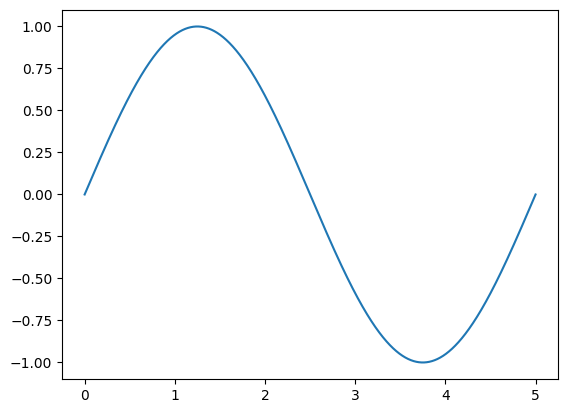

In [4]:
fs = 1.5e3
dt = 1/fs
duration = 5

cf = 1.5e3

t = np.linspace(0, duration, int(duration*fs))
s = np.sin(2*np.pi*t*cf)

plt.plot(t, s)

In [5]:
stimpar = {
    "dur": 0.26,
    "pip": 0.1,
    "start": [0.15],
    "baseline": [50, 150],
    "response": [150, 250],
}

In [6]:
f = 1.5e3
db = 60

In [7]:
stim = sound.TonePip(
    rate=100e3,
    duration=stimpar["dur"],
    f0=f,
    dbspl=db,
    ramp_duration=2.5e-3,
    pip_duration=stimpar["pip"],
    pip_start=stimpar["start"],
)

fs = int(0.5+1./stim.dt)
sr = 1
srgrp = [0,0,0]
srgrp[2-sr] = 1

sp = cochlea.run_zilany2014(
    stim.sound,
    fs=fs,
    anf_num=srgrp,
    cf=f,
    seed=seed,
    species='cat',
    cohc=1,
    cihc=1
)

(0.023441499999999803, 0.26)

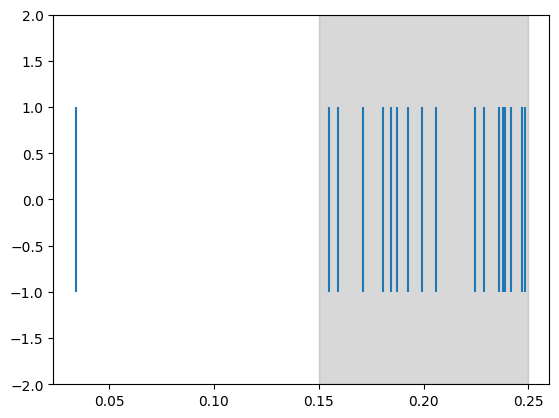

In [8]:
plt.vlines(sp.spikes.values[0],ymin=-1,ymax=1,zorder=12)
plt.axvspan(stimpar['start'][0],stimpar['start'][0]+stimpar['pip'],color='grey',alpha=0.3,zorder=1)
plt.ylim(-2,2)
plt.xlim(right=stimpar['dur'])

### Rate Level Curves

In [9]:
cohcs = np.round(np.arange(0.2,1.1,0.2), 1)
cihcs = np.round(np.arange(0.2,1.1,0.2), 1)

chc_combos = list(itertools.product(*[cohcs, cihcs]))

In [10]:
n_levels = 40   # 11
levels = np.insert(np.linspace(4, 100, n_levels) , 0, 0)

# c_hc = [(1,1), (0.1,1), (1,0.04), (0.1,0.04)]  # (outer, inner)

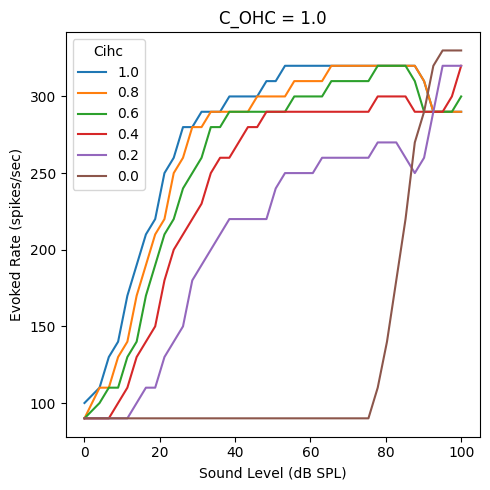

In [22]:
fs = int(0.5+1./stim.dt)
sr = 2
srgrp = [0,0,0]
srgrp[2-sr] = 1

level_spikes = {'level': [], 'spikes': []}

cohcs = [1.0]
cihcs = np.round(np.arange(0,1.1,0.2), 1)[::-1]

fig, axs = plt.subplots(1,len(cohcs),figsize=(len(cohcs)*5,5),sharey=True)
# axs = axs.ravel()

for i, cohc in enumerate(cohcs):
# for i, (cohc, cihc) in enumerate(chc_combos):

    for j, cihc in enumerate(cihcs):

        spike_rates = []

        for level in levels:
            stim = sound.TonePip(
                rate=100e3,
                duration=stimpar["dur"],
                f0=f,
                dbspl=level,
                ramp_duration=2.5e-3,
                pip_duration=stimpar["pip"],
                pip_start=stimpar["start"],
            )
            sp = cochlea.run_zilany2014(
                stim.sound,
                fs=fs,
                anf_num=srgrp,
                cf=f,
                seed=seed,
                species='cat',
                cohc=cohc,
                cihc=cihc
            )

            spikes = sp.spikes.values[0]
            num_spikes = ((spikes >= stimpar['start'][0]) & (spikes < stimpar['start'][0]+stimpar['pip'])).sum()
            spike_rates.append(num_spikes / stimpar['pip'])

        axs.plot(levels, spike_rates, label=cihc)
        axs.set_xlabel('Sound Level (dB SPL)')
        axs.set_title(f'C_OHC = {cohc}')
        
        axs.legend(loc='upper left', title='Cihc')
        # axs[i].set_ylim(bottom=-5)

    axs.set_ylabel('Evoked Rate (spikes/sec)')
    fig.tight_layout()
    fig.savefig('cihcs.png', dpi=300)
    fig.savefig('cihcs.pdf', dpi=300)

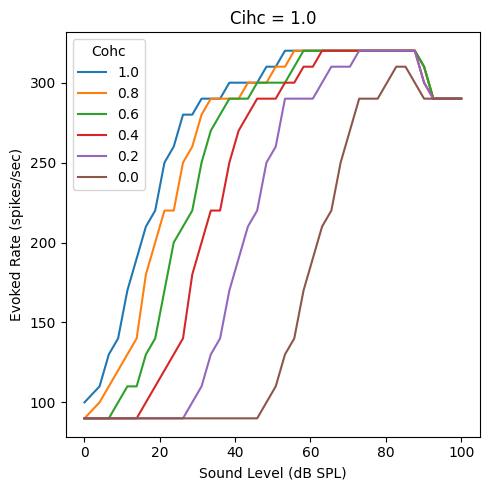

In [23]:
fs = int(0.5+1./stim.dt)
sr = 2
srgrp = [0,0,0]
srgrp[2-sr] = 1

level_spikes = {'level': [], 'spikes': []}

cohcs = np.round(np.arange(0,1.1,0.2), 1)[::-1]
cihcs = [1.0]

fig, axs = plt.subplots(1,len(cihcs),figsize=(len(cihcs)*5,5),sharey=True)
# axs = axs.ravel()

for i, cihc in enumerate(cihcs):
# for i, (cohc, cihc) in enumerate(chc_combos):

    for j, cohc in enumerate(cohcs):

        spike_rates = []

        for level in levels:
            stim = sound.TonePip(
                rate=100e3,
                duration=stimpar["dur"],
                f0=f,
                dbspl=level,
                ramp_duration=2.5e-3,
                pip_duration=stimpar["pip"],
                pip_start=stimpar["start"],
            )
            sp = cochlea.run_zilany2014(
                stim.sound,
                fs=fs,
                anf_num=srgrp,
                cf=f,
                seed=seed,
                species='cat',
                cohc=cohc,
                cihc=cihc
            )

            spikes = sp.spikes.values[0]
            num_spikes = ((spikes >= stimpar['start'][0]) & (spikes < stimpar['start'][0]+stimpar['pip'])).sum()
            spike_rates.append(num_spikes / stimpar['pip'])

        axs.plot(levels, spike_rates, label=cohc)
        axs.set_xlabel('Sound Level (dB SPL)')
        axs.set_title(f'Cihc = {cihc}')
        
        axs.legend(loc='upper left', title='Cohc')
        # axs[i].set_ylim(bottom=-5)

    axs.set_ylabel('Evoked Rate (spikes/sec)')
    fig.tight_layout()
    fig.savefig('cohcs.png', dpi=300)
    fig.savefig('cohcs.pdf', dpi=300)

### Spike Times

In [32]:
stimpar = {
    "dur": 0.26,
    "pip": 0.05,
    "start": [0.15],
    "baseline": [50, 150],
    "response": [150, 250],
}

In [ ]:
cohcs = np.round(np.arange(0.2,1.1,0.2), 1)
cihcs = np.round(np.arange(0.2,1.1,0.2), 1)

In [ ]:
n_levels = 40   # 11
levels = [60]

In [22]:
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple', 'tab:brown', 'tab:pink', 'tab:grey', 'tab:olive', 'tab:cyan']
cihc_colors = {cihc: colors[i] for i, cihc in enumerate(cihcs)}

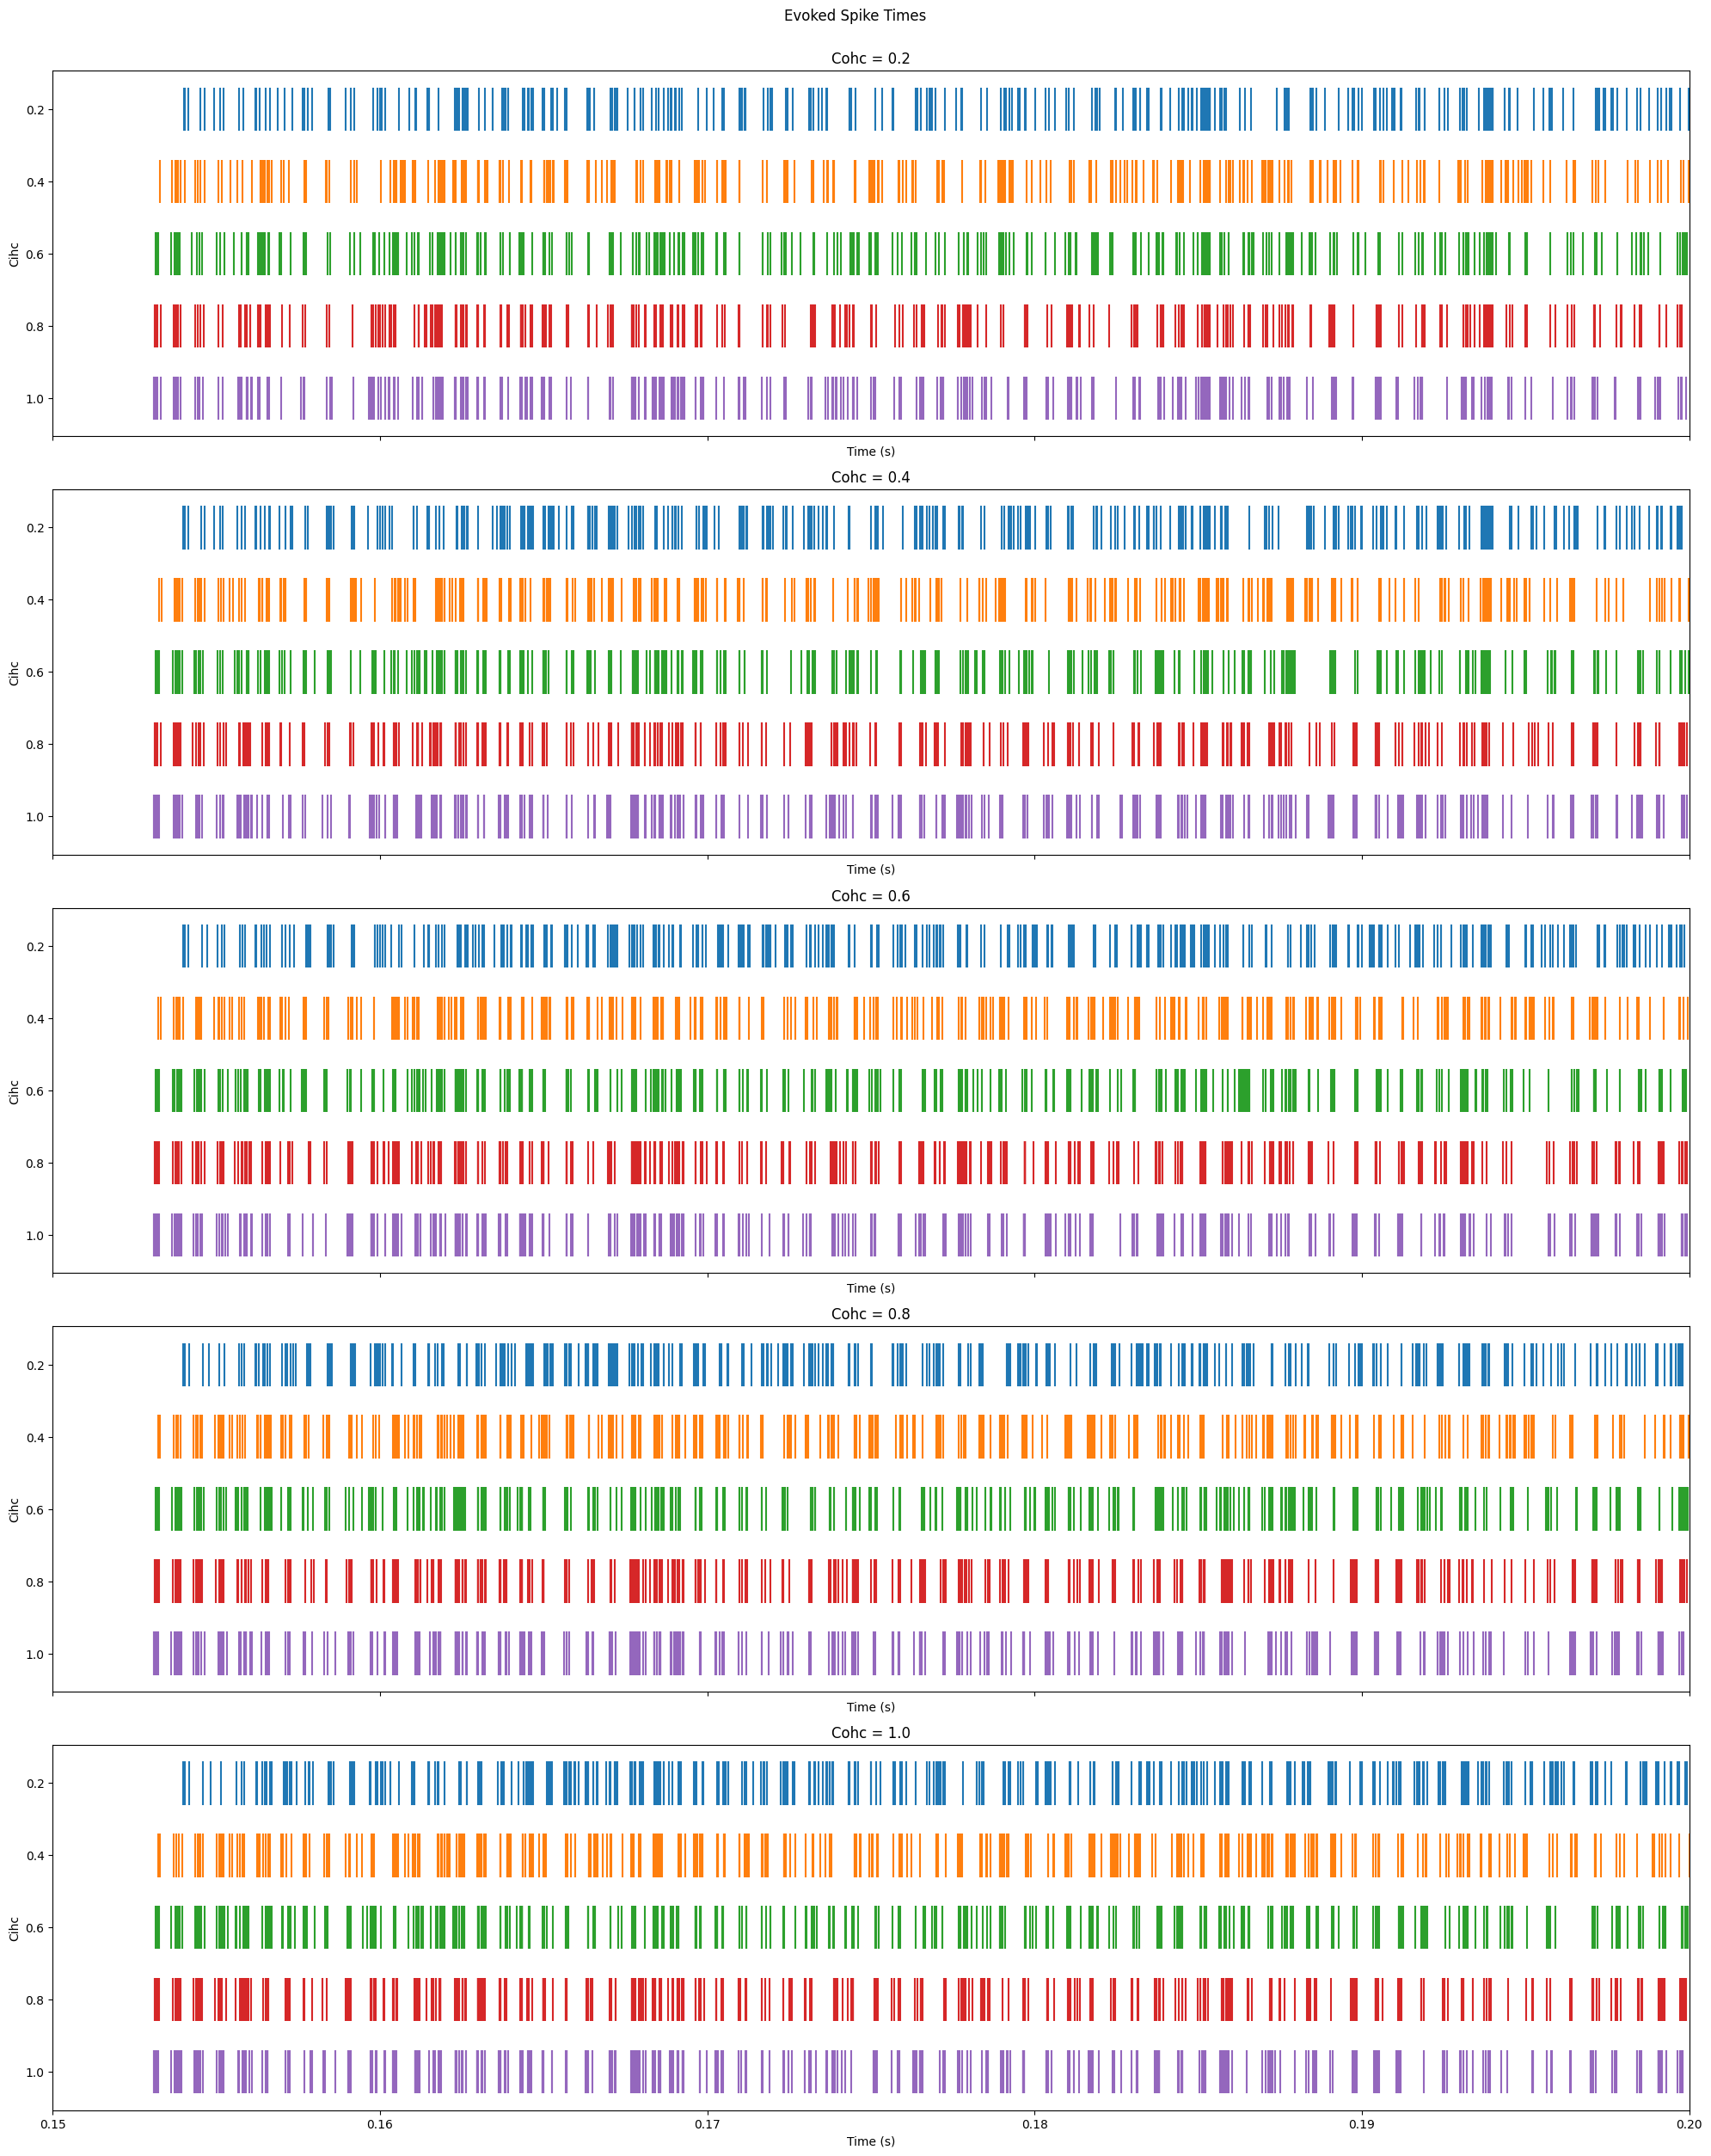

In [33]:
fs = int(0.5+1./stim.dt)
sr = 2
srgrp = [0,0,0]
srgrp[2-sr] = 1

level_spikes = {'level': [], 'spikes': []}

# fig, axs = plt.subplots(1,len(cohcs),figsize=(len(cohcs)*5,5),sharey=True,sharex=True)
fig, axs = plt.subplots(len(cohcs),1,figsize=(20,len(cohcs)*5),sharey=True,sharex=True)
axs = axs.ravel()

for i, cohc in enumerate(cohcs):
# for i, (cohc, cihc) in enumerate(chc_combos):

    for j, cihc in enumerate(cihcs):

        spike_rates = []

        for level in levels:
            stim = sound.TonePip(
                rate=100e3,
                duration=stimpar["dur"],
                f0=f,
                dbspl=level,
                ramp_duration=2.5e-3,
                pip_duration=stimpar["pip"],
                pip_start=stimpar["start"],
            )
            sp = cochlea.run_zilany2014(
                stim.sound,
                fs=fs,
                anf_num=srgrp,
                cf=f,
                seed=seed,
                species='cat',
                cohc=cohc,
                cihc=cihc
            )

            spikes = sp.spikes.values[0]

            axs[i].vlines(spikes,ymin=j-0.3,ymax=j+0.3,zorder=12, color=cihc_colors[cihc])

        # axs[i].axvspan(stimpar['start'][0],stimpar['start'][0]+stimpar['pip'],color='grey',alpha=0.03,zorder=1)
        axs[i].set_xlabel('Time (s)')
        axs[i].set_xlim(stimpar['start'][0],stimpar['start'][0]+stimpar['pip'])
        axs[i].set_title(f'Cohc = {cohc}')
        axs[i].set_ylabel('Cihc')
        
        # axs[i].legend(loc='upper left', title='Cihc')
        # axs[i].set_ylim(bottom=-5)
    # break

axs[0].set_yticks([i for i in range(len(cihcs))])
axs[0].set_yticklabels(cihcs)
axs[0].invert_yaxis()
fig.suptitle('Evoked Spike Times',y=1.001)
fig.tight_layout()

## Spontaneous Activity

In [12]:
stimpar = {
        "dur": 0.3,
        "pip": 0.1,
        "start": [0.125],       # equals response start in seconds
        "baseline": [25, 125],  # baseline duration has to equal response duration
        "response": [125, 225],
    }

In [13]:
f = 1.5e3
db = 120

stim = sound.TonePip(
    rate=100e3,
    duration=stimpar["dur"],
    f0=f,
    dbspl=db,
    ramp_duration=2.5e-3,
    pip_duration=stimpar["pip"],
    pip_start=stimpar["start"],
)

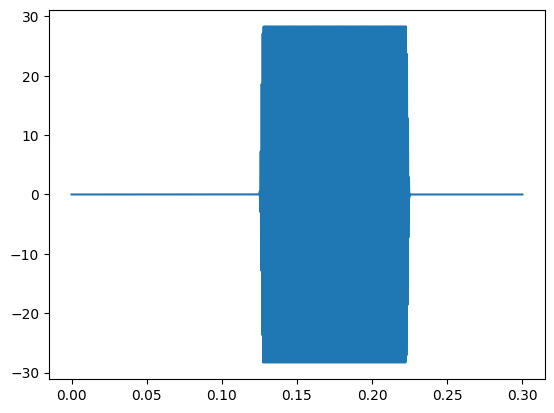

In [14]:
plt.plot(stim.time, stim.sound)

In [18]:
fs = int(0.5+1./stim.dt)
sr = 1
srgrp = [0,0,0]
srgrp[2-sr] = 3

sp = cochlea.run_zilany2014(
    stim.sound,
    fs=fs,
    anf_num=srgrp,
    cf=f,
    seed=seed,
    species='cat',
    cohc=1,
    cihc=1
)

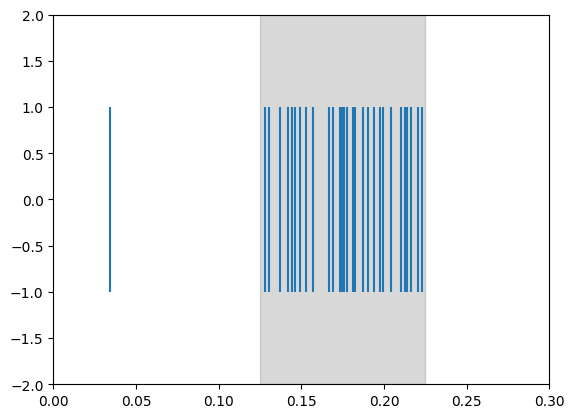

In [19]:
plt.vlines(sp.spikes.values[0],ymin=-1,ymax=1,zorder=12)
plt.axvspan(stimpar['start'][0],stimpar['start'][0]+stimpar['pip'],color='grey',alpha=0.3,zorder=1)
plt.ylim(-2,2)
plt.xlim(0,stimpar['dur']);

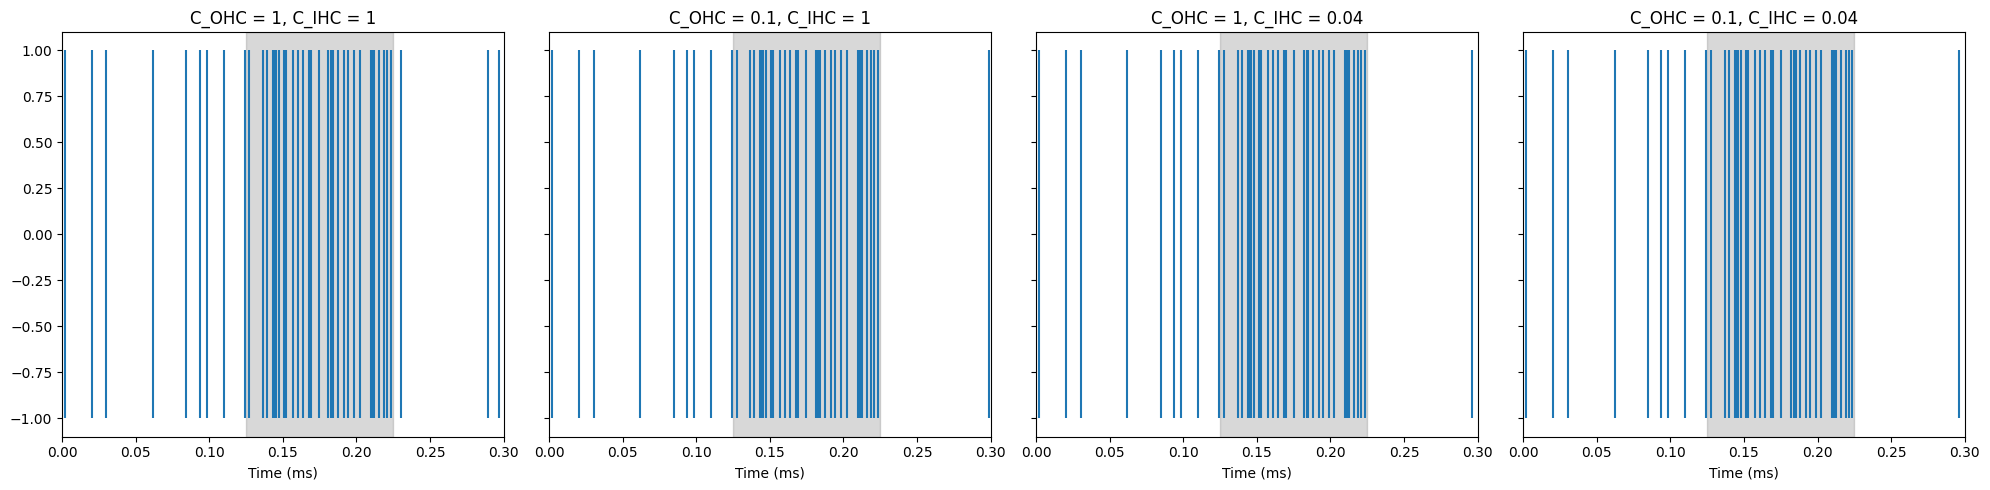

In [53]:
fs = int(0.5+1./stim.dt)
sr = 2
srgrp = [0,0,0]
srgrp[2-sr] = 1

level_spikes = {'level': [], 'spikes': []}

c_hc = [(1,1), (0.1,1), (1,0.04), (0.1,0.04)]

fig, axs = plt.subplots(1,len(c_hc),figsize=(len(c_hc)*5,5),sharey=True)
axs = axs.ravel()

for i, (cohc, cihc) in enumerate(c_hc):

    spike_rates = []

    stim = sound.TonePip(
        rate=100e3,
        duration=stimpar["dur"],
        f0=f,
        dbspl=db,
        ramp_duration=2.5e-3,
        pip_duration=stimpar["pip"],
        pip_start=stimpar["start"],
    )
    sp = cochlea.run_zilany2014(
        stim.sound,
        fs=fs,
        anf_num=srgrp,
        cf=f,
        seed=seed,
        species='cat',
        cohc=cohc,
        cihc=cihc
    )

    spikes = sp.spikes.values[0]

    axs[i].axvspan(stimpar['start'][0],stimpar['start'][0]+stimpar['pip'],color='grey',alpha=0.3,zorder=1)
    axs[i].vlines(sp.spikes.values[0],ymin=-1,ymax=1,zorder=12)
    axs[i].set_xlabel('Time (ms)')
    axs[i].set_xlim(0,stimpar['dur'])
    axs[i].set_title(f'C_OHC = {cohc}, C_IHC = {cihc}')
    # axs[i].set_ylim(bottom=-5)

# axs[0].set_ylabel('Rate (spikes/sec)')
fig.tight_layout()

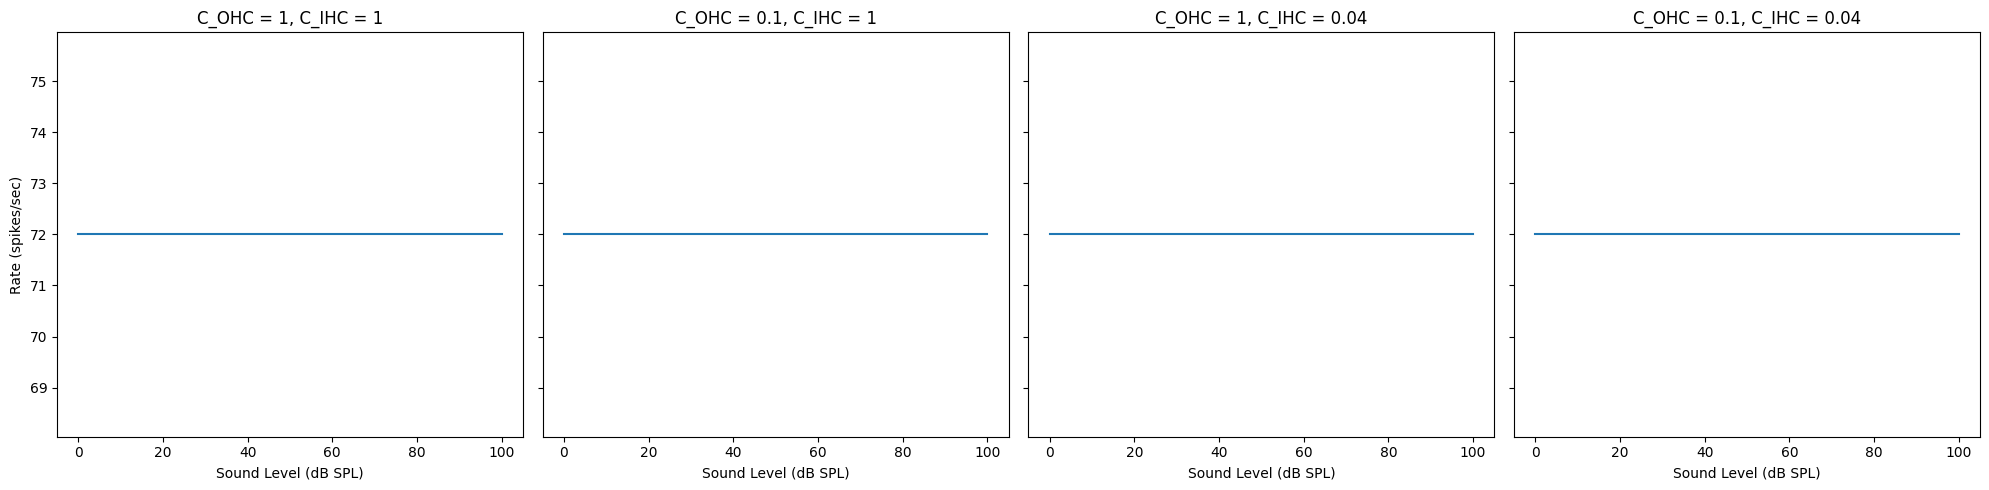

In [21]:
fs = int(0.5+1./stim.dt)
sr = 2
srgrp = [0,0,0]
srgrp[2-sr] = 1

n_levels = 40   # 11
levels = np.insert(np.linspace(4, 100, n_levels) , 0, 0)

level_spikes = {'level': [], 'spikes': []}

c_hc = [(1,1), (0.1,1), (1,0.04), (0.1,0.04)]

fig, axs = plt.subplots(1,len(c_hc),figsize=(len(c_hc)*5,5),sharey=True)
axs = axs.ravel()

for i, (cohc, cihc) in enumerate(c_hc):

    spike_rates = []

    for level in levels:
        stim = sound.TonePip(
            rate=100e3,
            duration=stimpar["dur"],
            f0=f,
            dbspl=db,
            ramp_duration=2.5e-3,
            pip_duration=stimpar["pip"],
            pip_start=stimpar["start"],
        )
        sp = cochlea.run_zilany2014(
            stim.sound,
            fs=fs,
            anf_num=srgrp,
            cf=f,
            seed=seed,
            species='cat',
            cohc=cohc,
            cihc=cihc
        )

        spikes = sp.spikes.values[0]
        num_spikes = ((spikes >= [0]) & (spikes < stimpar['start'][0])).sum()
        spike_rates.append(num_spikes / stimpar['start'][0])

    axs[i].plot(levels, spike_rates)
    axs[i].set_xlabel('Sound Level (dB SPL)')
    axs[i].set_title(f'C_OHC = {cohc}, C_IHC = {cihc}')
    # axs[i].set_ylim(bottom=-5)

axs[0].set_ylabel('Rate (spikes/sec)')
fig.tight_layout()

In [7]:
stimpar

{'dur': 0.3,
 'pip': 0.1,
 'start': [0.125],
 'baseline': [25, 125],
 'response': [125, 225]}

# PCA Network

## 22kHz input, 13kHz loss

In [7]:
cf_fmin = 4e3 
cf_fmax = 40e3
cf_octavespacing = 1 / 200.0  # 0.5 -> 2, 1 -> 4, 16 -> 66, 32 -> 107, 64 -> 213, 200 -> 665
cf_n_frequencies = int(np.log2(cf_fmax / cf_fmin) / cf_octavespacing) + 1
cf_fvals = (
    np.logspace(
        np.log2(cf_fmin / 1000.0),
        np.log2(cf_fmax / 1000.0),
        num=cf_n_frequencies,
        endpoint=True,
        base=2,
    )
    * 1000.0
)

In [8]:
n_levels = 11  # 2 for debugging, 11 for full
levels = np.linspace(20, 100, n_levels)

In [9]:
stimpar = {
    "dur": 0.26,
    "pip": 0.1,
    "start": [0.1],
    "baseline": [50, 150],
    "response": [150, 250],
}

input_frequency = 22e3

### Normal Hearing

In [10]:
stim_avg_rates = pickle.load(open('/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band = pickle.load(open('/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs = list(pyramidal_ids_per_band.keys())
b = (freqs[-1] - freqs[0]) / np.log(freqs[-1] / freqs[0])
a = freqs[0] - b * np.log(freqs[0])
freqs_log = a + b * np.log(freqs)

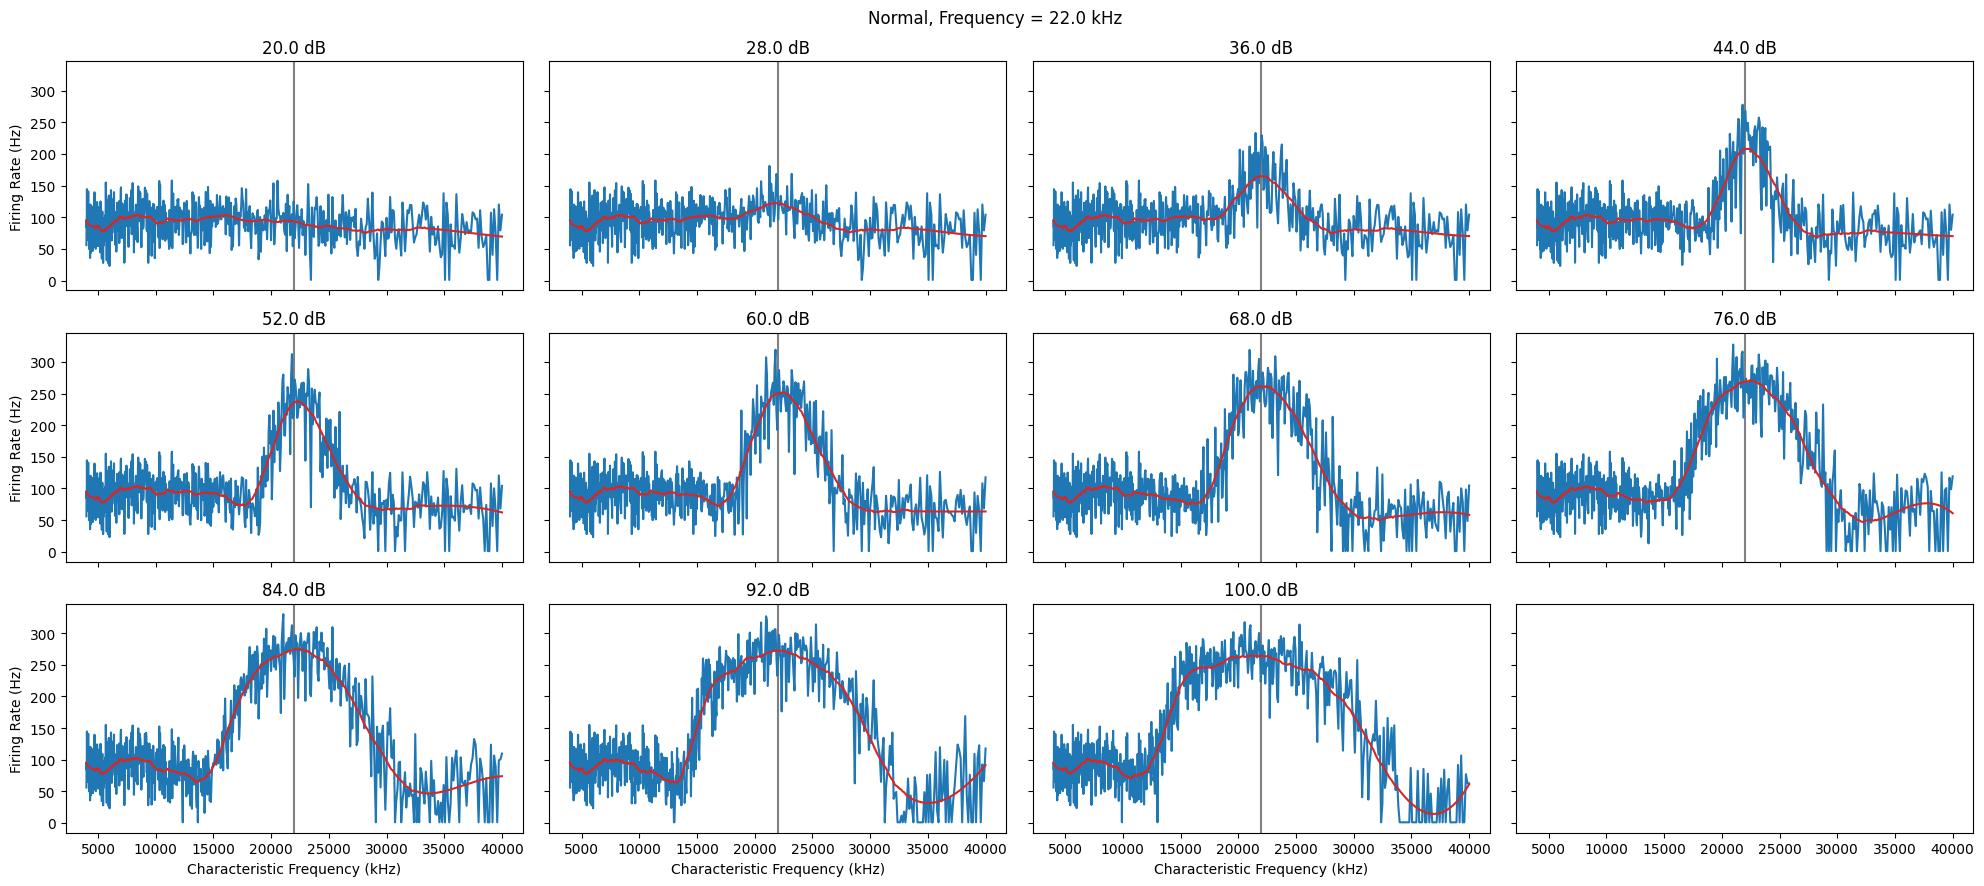

In [11]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Normal, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

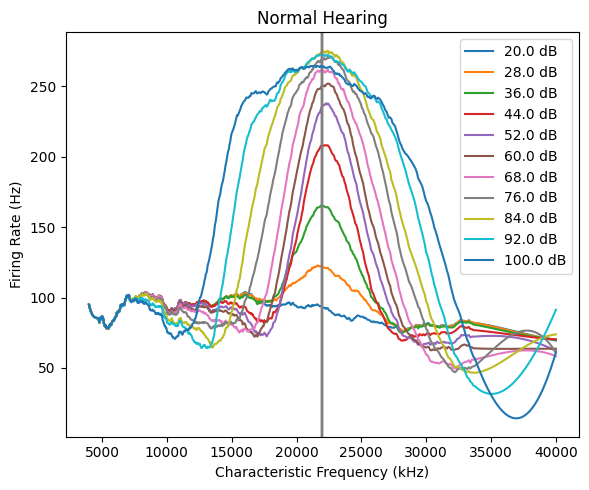

In [12]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title('Normal Hearing')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig('pyramidal_array_firing_rates-normal.png', dpi=300)

### Hearing Loss

#### C_OHC = 0.1, C_IHC = 1.0

In [13]:
cohc1 = 0.1
cihc1 = 1.0

loss = 13000

stim_avg_rates_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}_13000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}_13000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss1 = list(pyramidal_ids_per_band_loss1.keys())
b = (freqs_loss1[-1] - freqs_loss1[0]) / np.log(freqs_loss1[-1] / freqs_loss1[0])
a = freqs_loss1[0] - b * np.log(freqs_loss1[0])
freqs_log_loss1 = a + b * np.log(freqs_loss1)

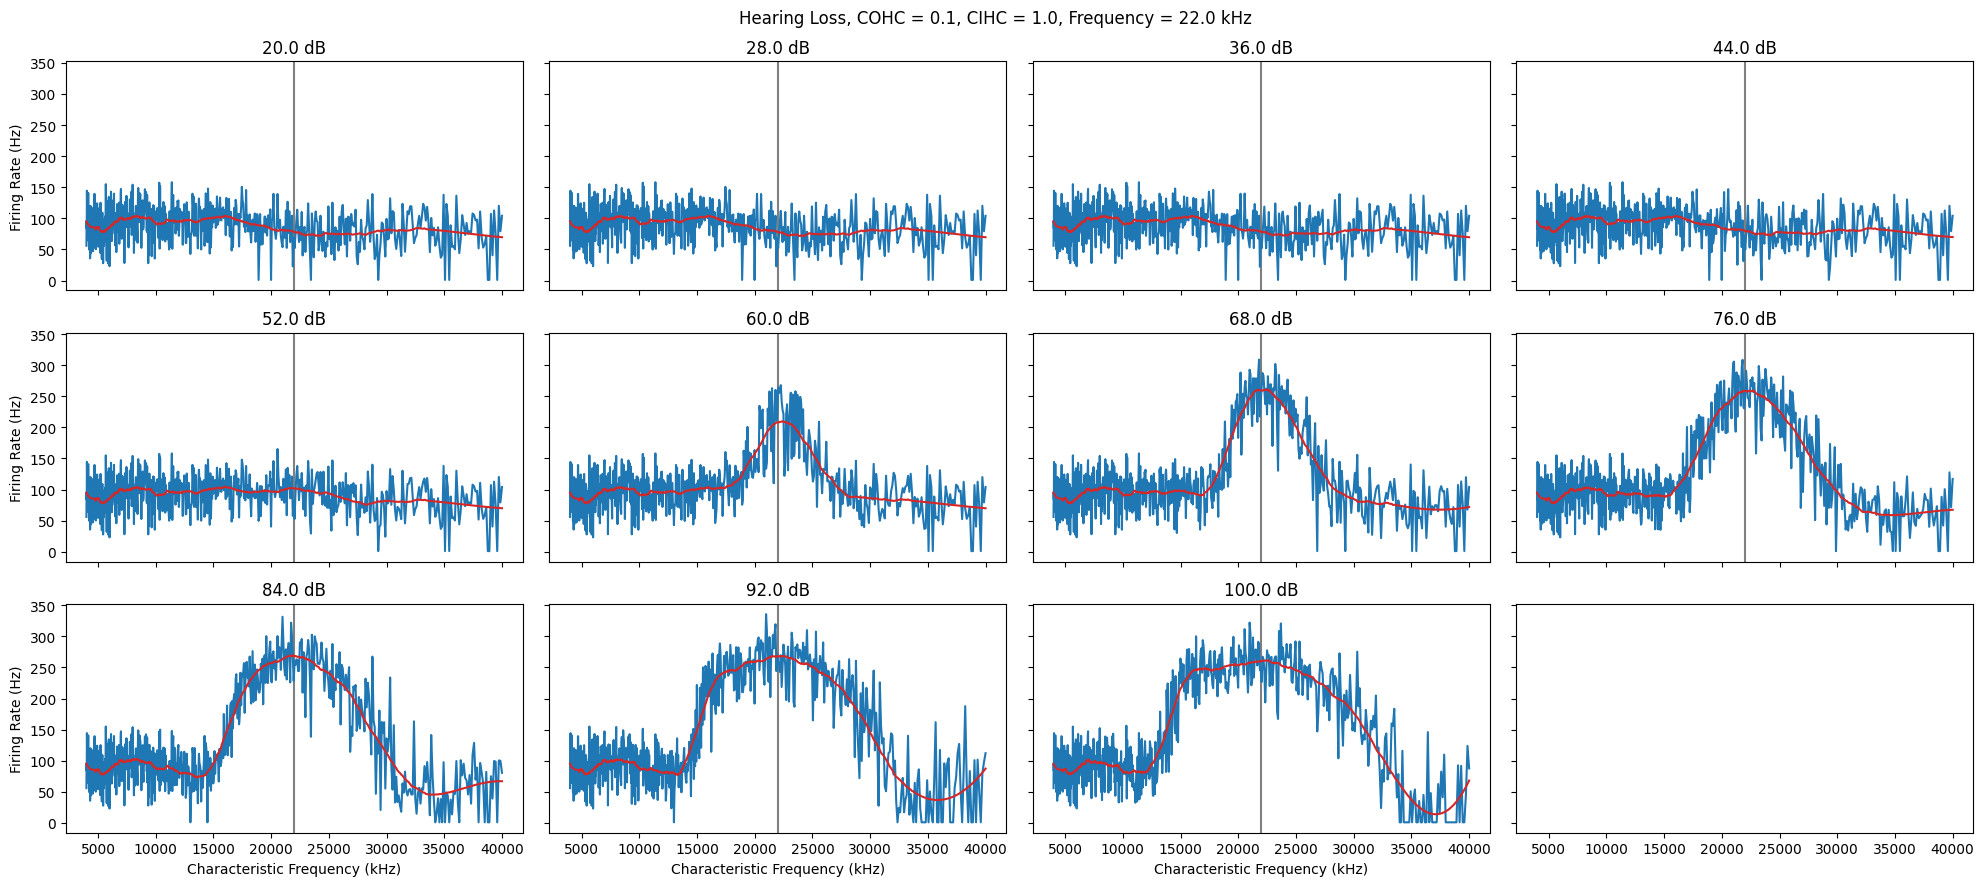

In [14]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss1)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates_loss1.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Hearing Loss, COHC = {cohc1}, CIHC = {cihc1}, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

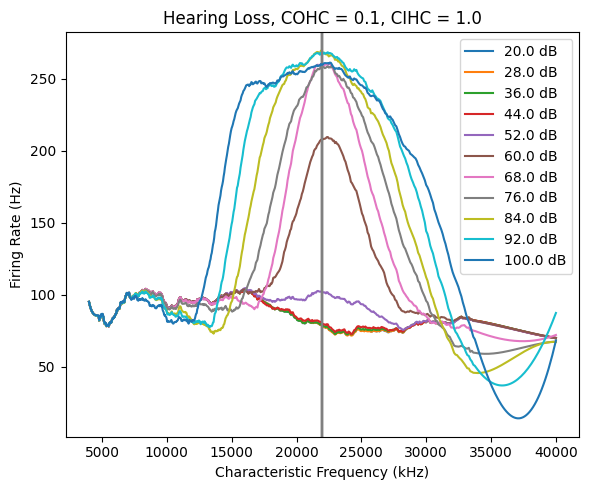

In [15]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates_loss1.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title(f'Hearing Loss, COHC = {cohc1}, CIHC = {cihc1}')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig(f'pyramidal_array_firing_rates-loss-cohc_{cohc1}-cihc{cihc1}.png', dpi=300)

#### COHC = 1.0, CIHC = 0.04

In [16]:
cohc2 = 1.0
cihc2 = 0.04

stim_avg_rates_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}_13000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}_13000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss2 = list(pyramidal_ids_per_band_loss2.keys())
b = (freqs_loss2[-1] - freqs_loss2[0]) / np.log(freqs_loss2[-1] / freqs_loss2[0])
a = freqs_loss2[0] - b * np.log(freqs_loss2[0])
freqs_log_loss2 = a + b * np.log(freqs_loss2)

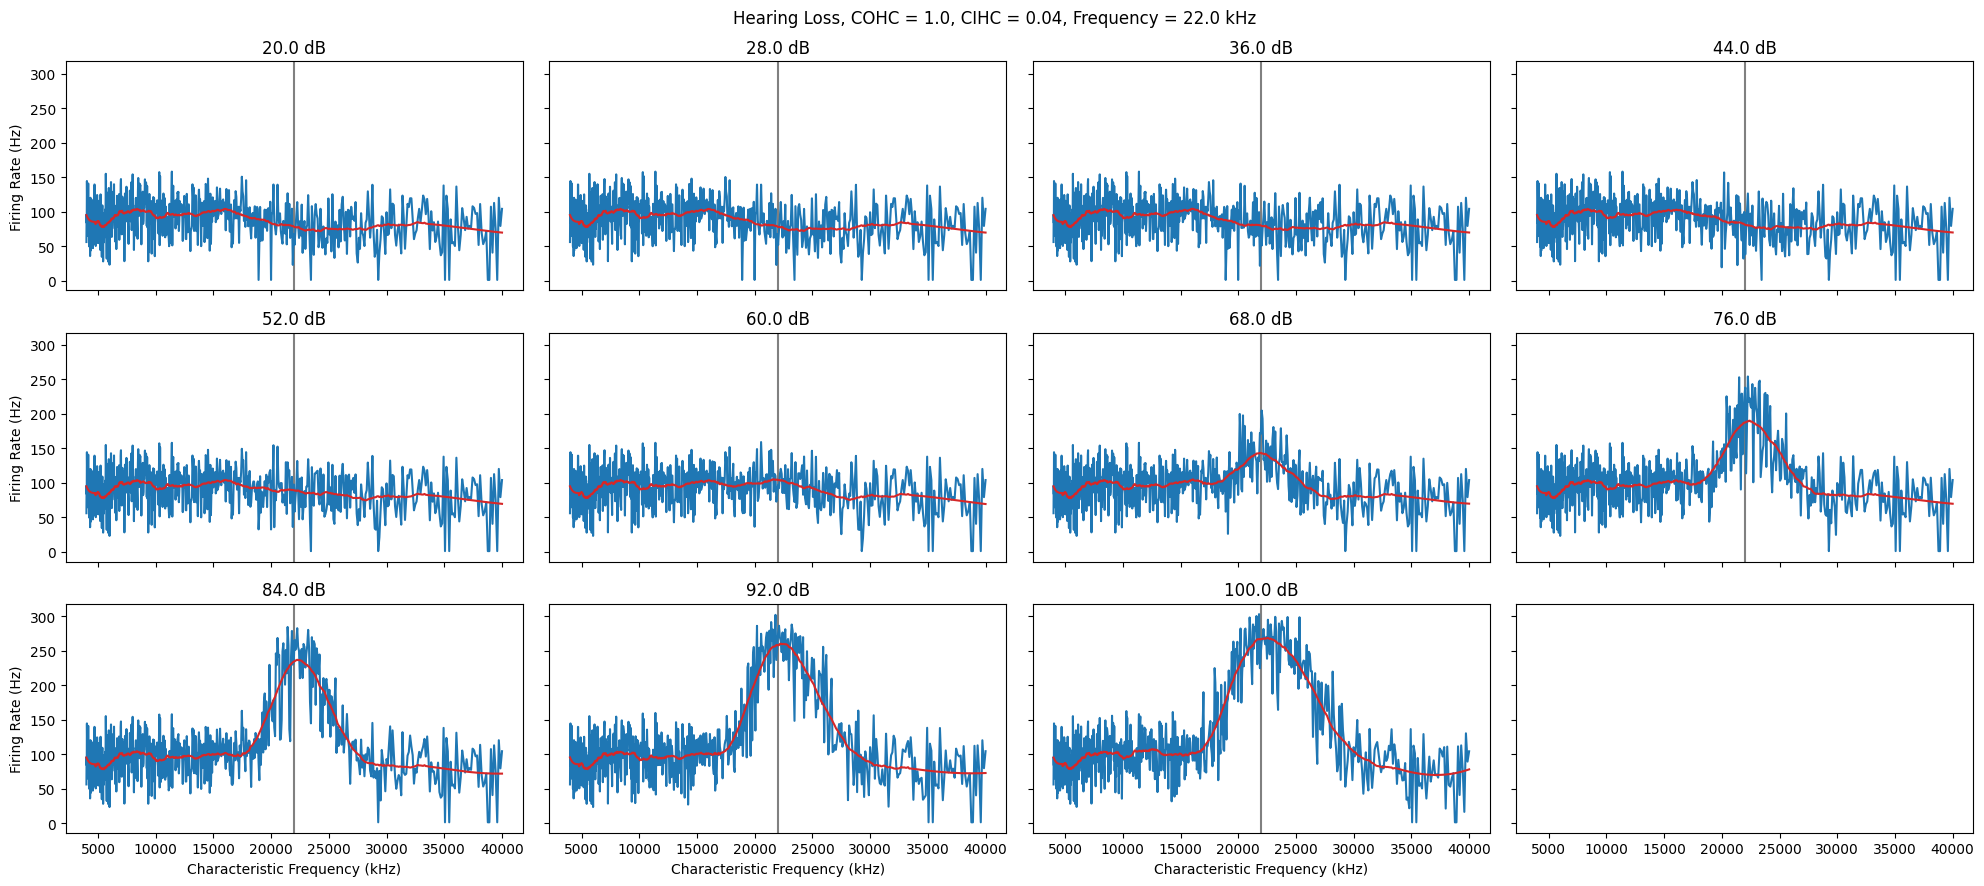

In [17]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss2)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates_loss2.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Hearing Loss, COHC = {cohc2}, CIHC = {cihc2}, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

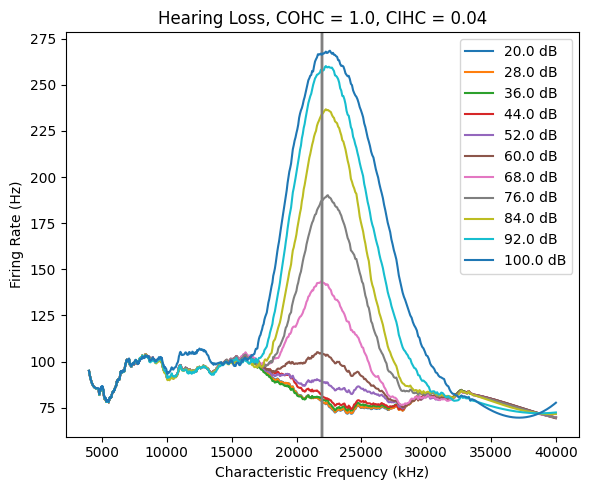

In [18]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates_loss2.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title(f'Hearing Loss, COHC = {cohc2}, CIHC = {cihc2}')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig(f'pyramidal_array_firing_rates-loss-cohc_{cohc2}-cihc{cihc2}.png', dpi=300)

#### COHC = 0.1, CIHC = 0.04

In [19]:
cohc3 = 0.1
cihc3 = 0.04

stim_avg_rates_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}_13000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}_13000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss3 = list(pyramidal_ids_per_band_loss3.keys())
b = (freqs_loss3[-1] - freqs_loss3[0]) / np.log(freqs_loss3[-1] / freqs_loss3[0])
a = freqs_loss3[0] - b * np.log(freqs_loss3[0])
freqs_log_loss3 = a + b * np.log(freqs_loss3)

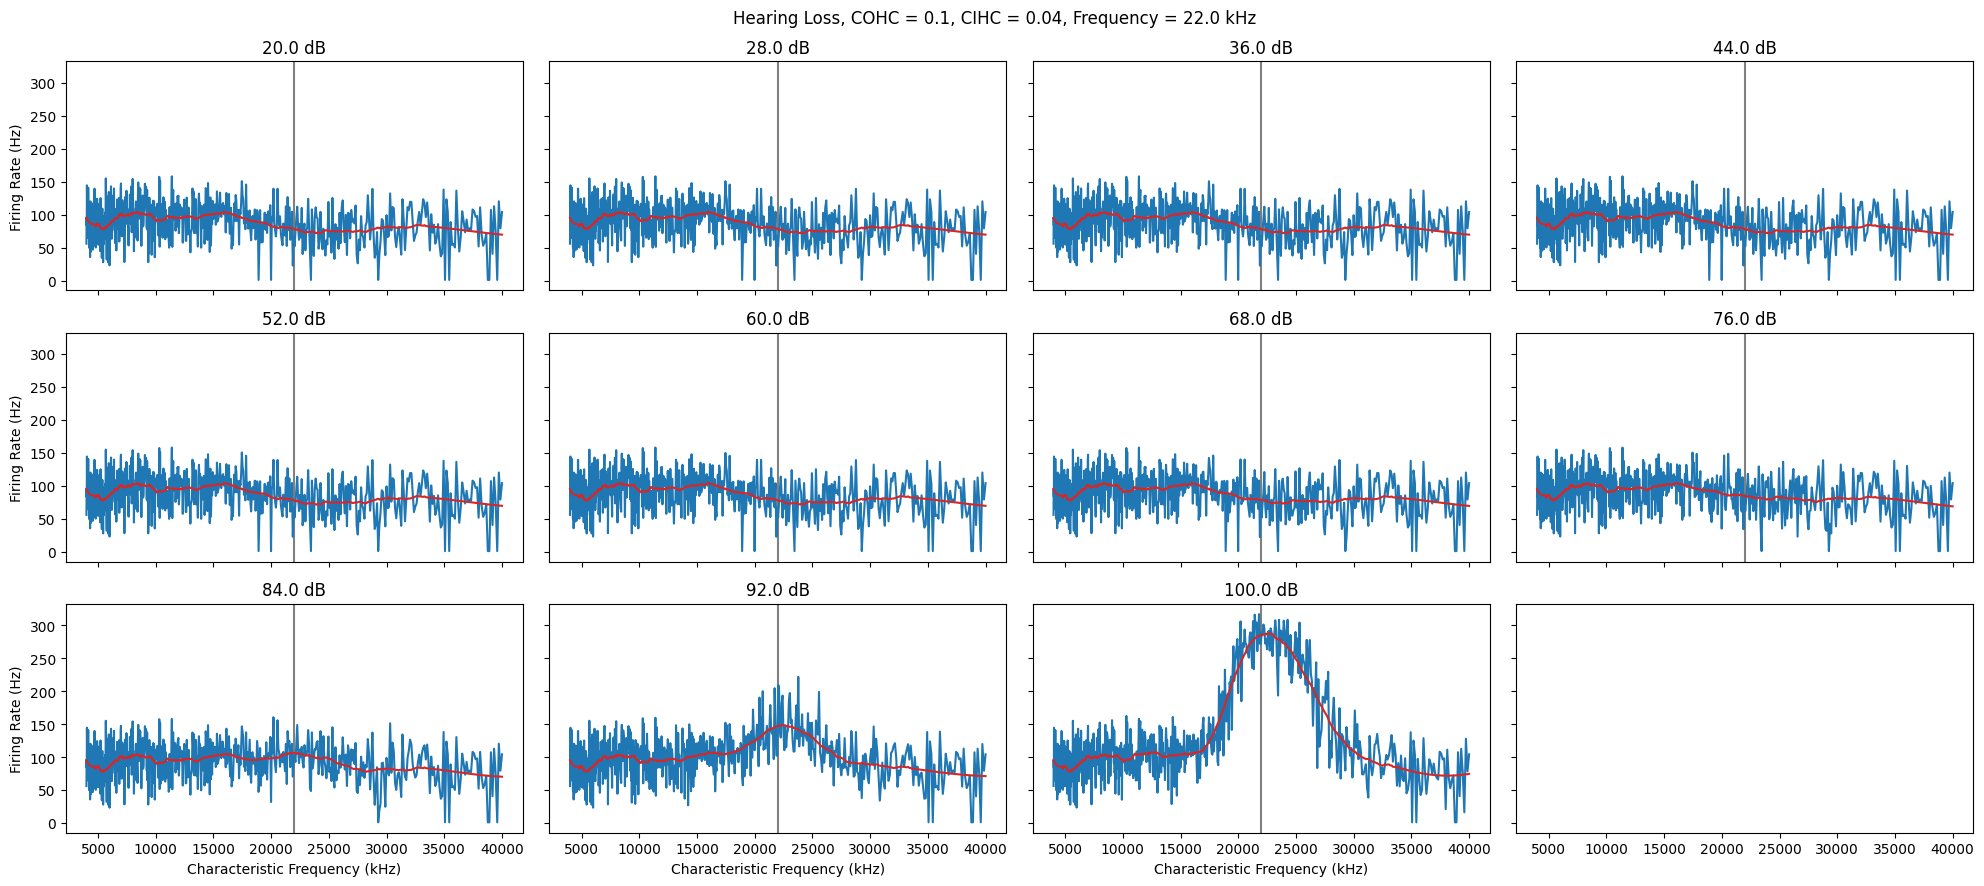

In [20]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss3)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates_loss3.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

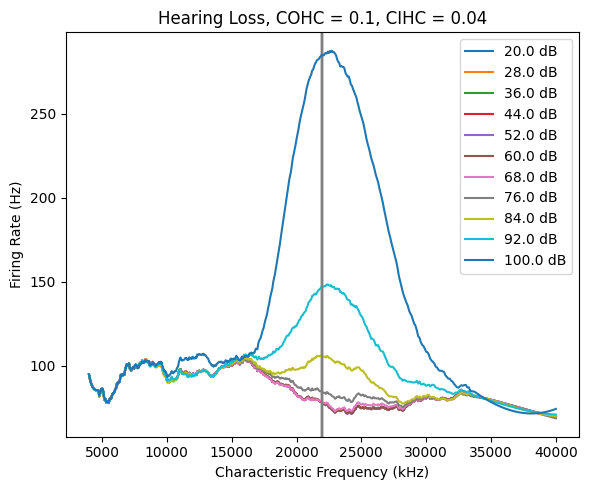

In [21]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates_loss3.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig(f'pyramidal_array_firing_rates-loss-cohc_{cohc3}-cihc{cihc3}.png', dpi=300)


### All

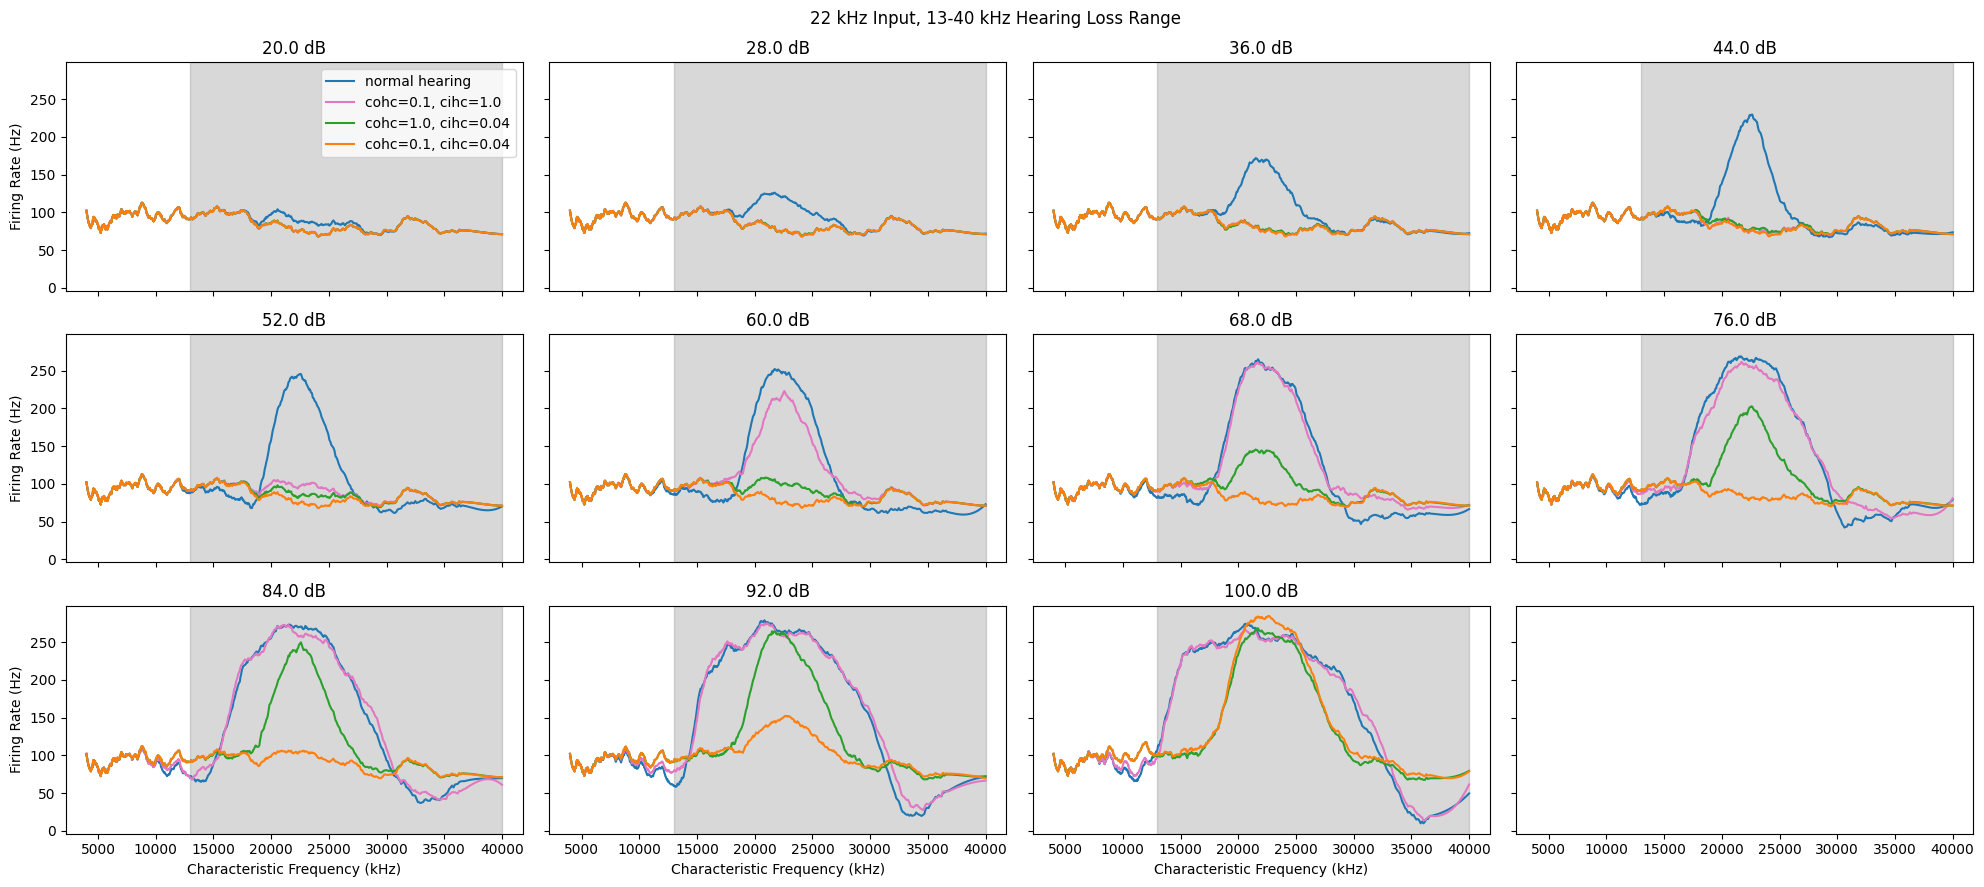

In [22]:
colors = ['tab:blue', 'tab:pink', 'tab:green', 'tab:orange']

n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss3)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, stim_rates in enumerate(zip(stim_avg_rates.items(), stim_avg_rates_loss1.items(), stim_avg_rates_loss2.items(), stim_avg_rates_loss3.items())):
    
    level = stim_rates[0][0].opts['dbspl']

    window = 50
    axs[i].plot(freqs, savgol_filter(stim_rates[0][1], window, 3), color=colors[0], label='normal hearing')
    axs[i].plot(freqs, savgol_filter(stim_rates[1][1], window, 3), color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    axs[i].plot(freqs, savgol_filter(stim_rates[2][1], window, 3), color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    axs[i].plot(freqs, savgol_filter(stim_rates[3][1], window, 3), color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    # axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].axvspan(loss, freqs[-1], color='grey', alpha=0.3, zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
axs[0].legend(loc='upper right')  #, bbox_to_anchor=(1, 1))
# fig.set_dpi(300)
# fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.suptitle('22 kHz Input, 13-40 kHz Hearing Loss Range')
fig.tight_layout()

## Type III - 22kHz input, 13kHz loss

### All

In [2]:
syns = '-SPx0.00044_VPx0.0006'

stim_avg_rates = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0{syns}/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0{syns}/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs = list(pyramidal_ids_per_band.keys())
b = (freqs[-1] - freqs[0]) / np.log(freqs[-1] / freqs[0])
a = freqs[0] - b * np.log(freqs[0])
freqs_log = a + b * np.log(freqs)

In [3]:
cohc1 = 0.1
cihc1 = 1.0

loss = 13000

stim_avg_rates_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss1 = list(pyramidal_ids_per_band_loss1.keys())
b = (freqs_loss1[-1] - freqs_loss1[0]) / np.log(freqs_loss1[-1] / freqs_loss1[0])
a = freqs_loss1[0] - b * np.log(freqs_loss1[0])
freqs_log_loss1 = a + b * np.log(freqs_loss1)

In [4]:
cohc2 = 1.0
cihc2 = 0.04

stim_avg_rates_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss2 = list(pyramidal_ids_per_band_loss2.keys())
b = (freqs_loss2[-1] - freqs_loss2[0]) / np.log(freqs_loss2[-1] / freqs_loss2[0])
a = freqs_loss2[0] - b * np.log(freqs_loss2[0])
freqs_log_loss2 = a + b * np.log(freqs_loss2)

In [5]:
cohc3 = 0.1
cihc3 = 0.04

stim_avg_rates_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss3 = list(pyramidal_ids_per_band_loss3.keys())
b = (freqs_loss3[-1] - freqs_loss3[0]) / np.log(freqs_loss3[-1] / freqs_loss3[0])
a = freqs_loss3[0] - b * np.log(freqs_loss3[0])
freqs_log_loss3 = a + b * np.log(freqs_loss3)

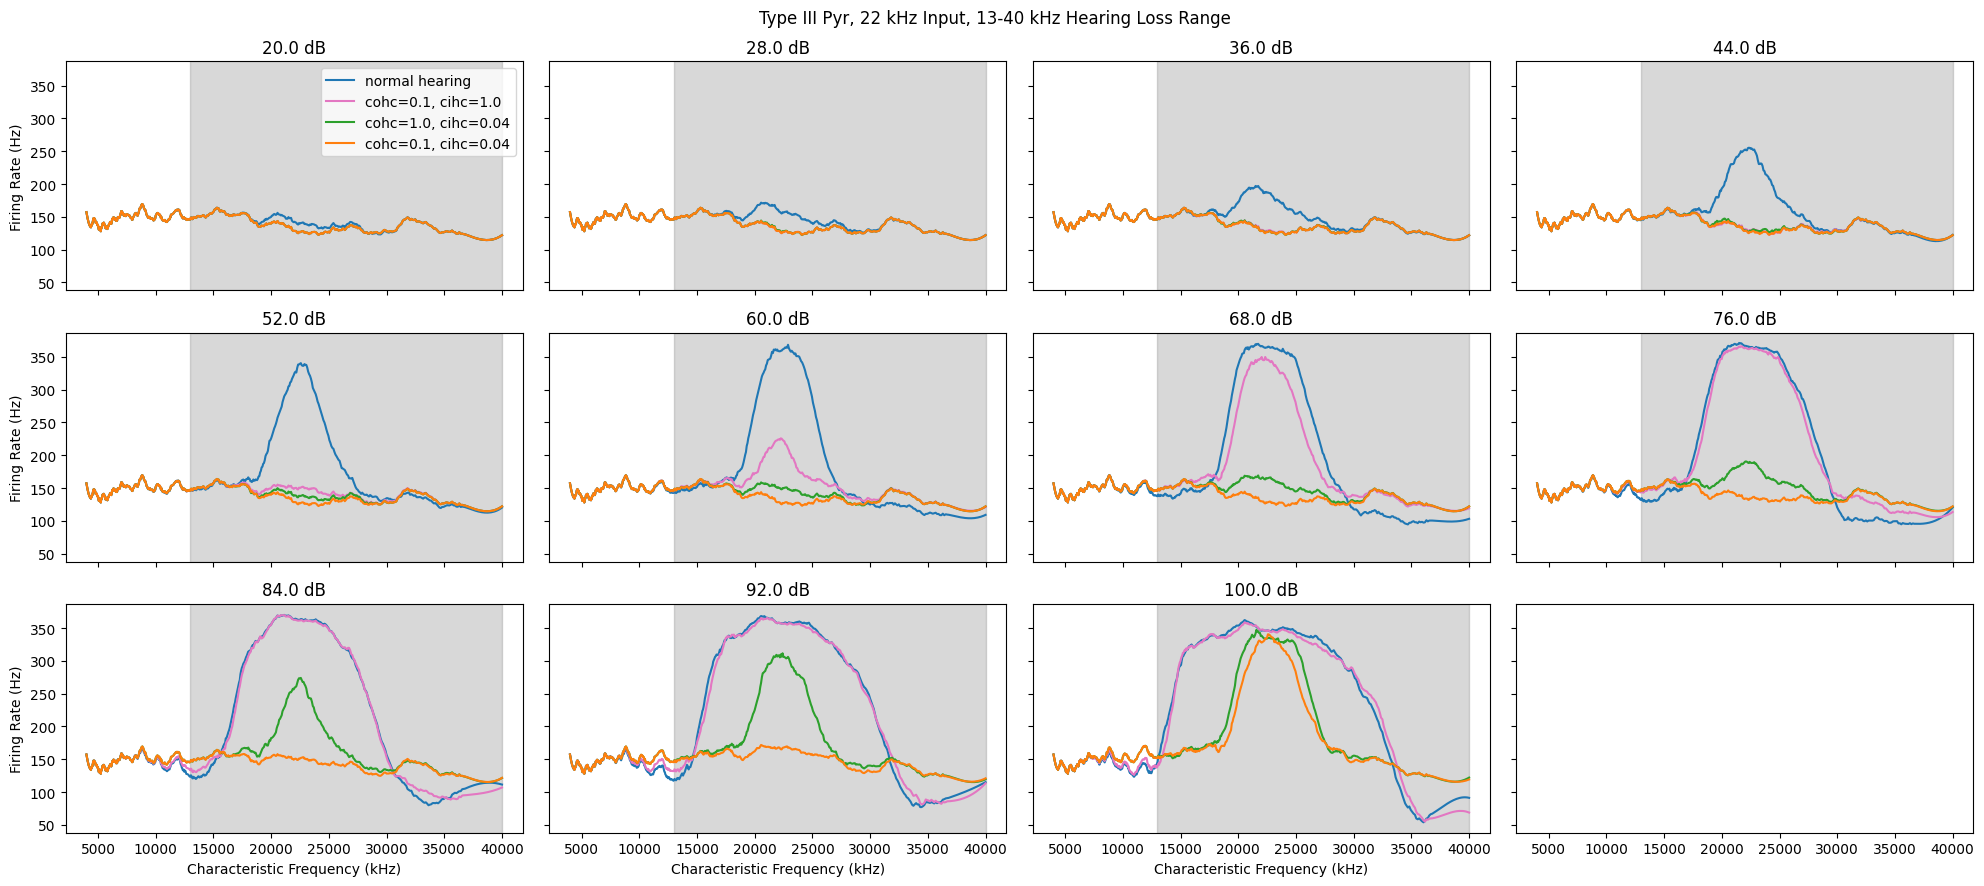

In [6]:
colors = ['tab:blue', 'tab:pink', 'tab:green', 'tab:orange']

n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss3)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, stim_rates in enumerate(zip(stim_avg_rates.items(), stim_avg_rates_loss1.items(), stim_avg_rates_loss2.items(), stim_avg_rates_loss3.items())):
    
    level = stim_rates[0][0].opts['dbspl']

    window = 50
    axs[i].plot(freqs, savgol_filter(stim_rates[0][1], window, 3), color=colors[0], label='normal hearing')
    axs[i].plot(freqs, savgol_filter(stim_rates[1][1], window, 3), color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    axs[i].plot(freqs, savgol_filter(stim_rates[2][1], window, 3), color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    axs[i].plot(freqs, savgol_filter(stim_rates[3][1], window, 3), color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')

    # axs[i].plot(freqs_log, stim_rates[0][1], color=colors[0], label='normal hearing')
    # axs[i].plot(freqs_log, stim_rates[1][1], color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    # axs[i].plot(freqs_log, stim_rates[2][1], color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    # axs[i].plot(freqs_log, stim_rates[3][1], color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvspan(loss, freqs[-1], color='grey', alpha=0.3, zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')

# axs[i].set_xlim(left=20000)
# axs[0].set_ylim([40,310])

axs[0].legend(loc='upper right')  #, bbox_to_anchor=(1, 1))
# fig.set_dpi(300)
# fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.suptitle('Type III Pyr, 22 kHz Input, 13-40 kHz Hearing Loss Range')
fig.tight_layout()

## Type IV - 22kHz Input, 13kHz loss

### All

In [2]:
syns = '-SPx0.00038_VPx0.0039'

stim_avg_rates = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0{syns}/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0{syns}/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs = list(pyramidal_ids_per_band.keys())
b = (freqs[-1] - freqs[0]) / np.log(freqs[-1] / freqs[0])
a = freqs[0] - b * np.log(freqs[0])
freqs_log = a + b * np.log(freqs)

In [3]:
cohc1 = 0.1
cihc1 = 1.0

loss = 13000

stim_avg_rates_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss1 = list(pyramidal_ids_per_band_loss1.keys())
b = (freqs_loss1[-1] - freqs_loss1[0]) / np.log(freqs_loss1[-1] / freqs_loss1[0])
a = freqs_loss1[0] - b * np.log(freqs_loss1[0])
freqs_log_loss1 = a + b * np.log(freqs_loss1)

In [4]:
cohc2 = 1.0
cihc2 = 0.04

stim_avg_rates_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss2 = list(pyramidal_ids_per_band_loss2.keys())
b = (freqs_loss2[-1] - freqs_loss2[0]) / np.log(freqs_loss2[-1] / freqs_loss2[0])
a = freqs_loss2[0] - b * np.log(freqs_loss2[0])
freqs_log_loss2 = a + b * np.log(freqs_loss2)

In [5]:
cohc3 = 0.1
cihc3 = 0.04

stim_avg_rates_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}{syns}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}_{loss}loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss3 = list(pyramidal_ids_per_band_loss3.keys())
b = (freqs_loss3[-1] - freqs_loss3[0]) / np.log(freqs_loss3[-1] / freqs_loss3[0])
a = freqs_loss3[0] - b * np.log(freqs_loss3[0])
freqs_log_loss3 = a + b * np.log(freqs_loss3)

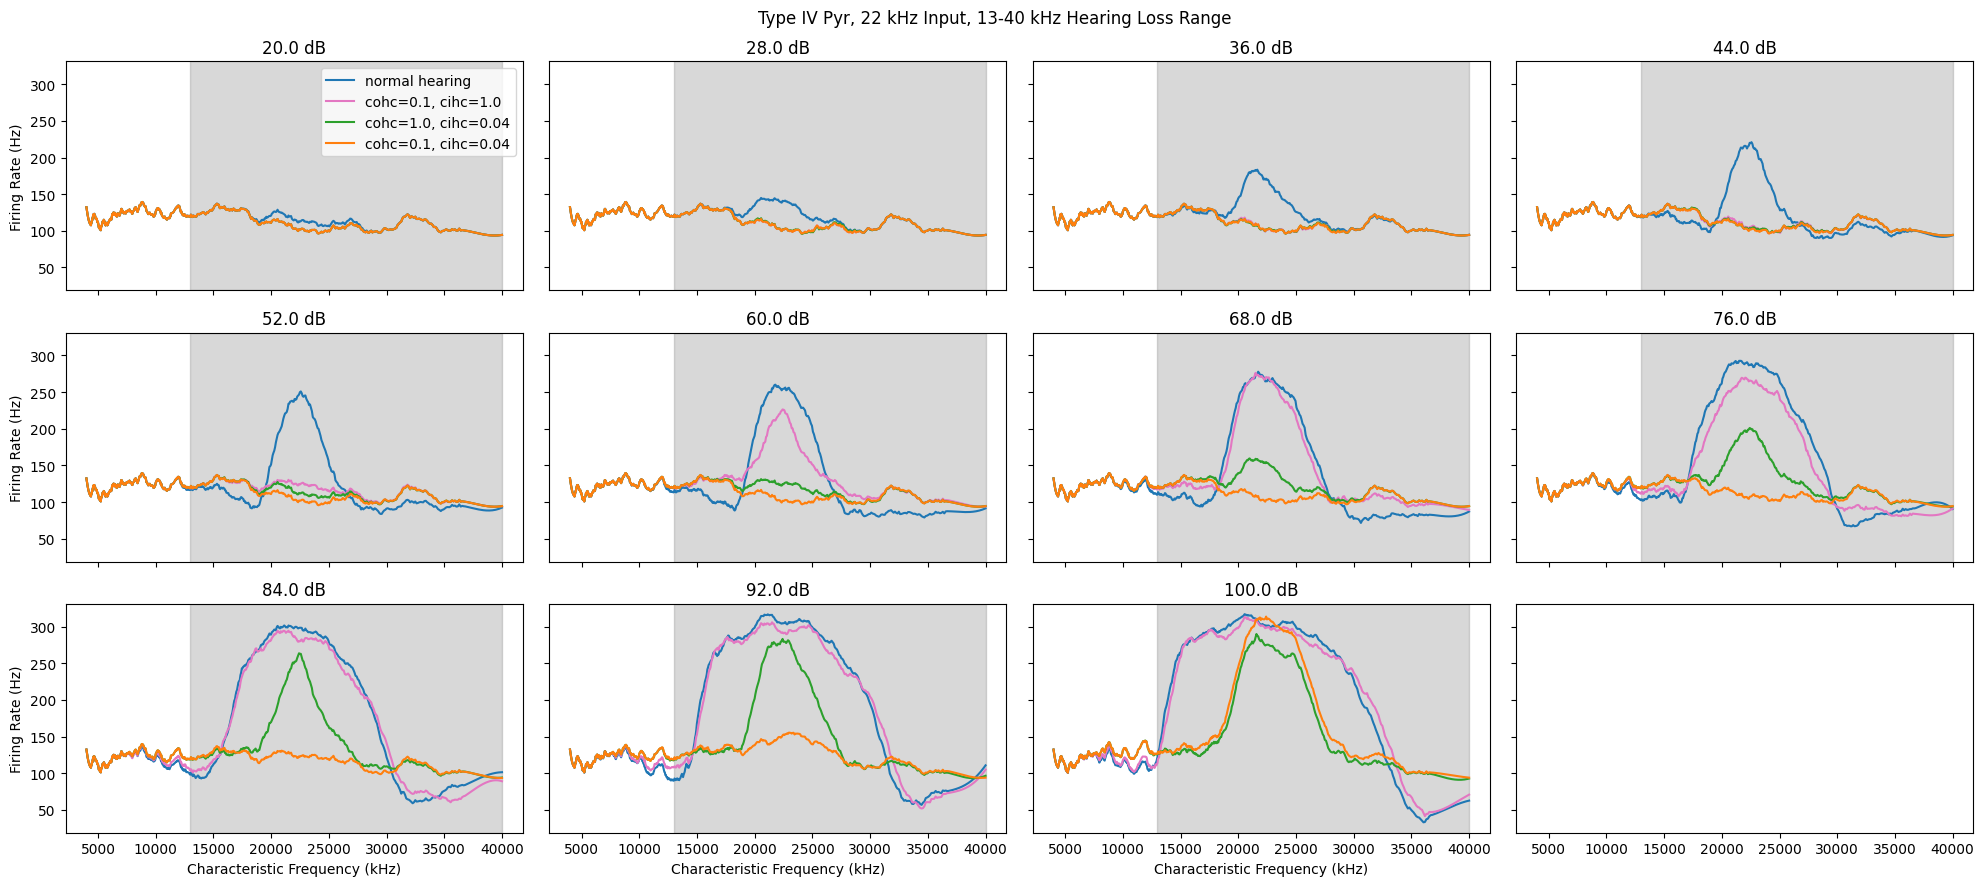

In [7]:
colors = ['tab:blue', 'tab:pink', 'tab:green', 'tab:orange']

n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss3)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, stim_rates in enumerate(zip(stim_avg_rates.items(), stim_avg_rates_loss1.items(), stim_avg_rates_loss2.items(), stim_avg_rates_loss3.items())):
    
    level = stim_rates[0][0].opts['dbspl']

    window = 50
    axs[i].plot(freqs, savgol_filter(stim_rates[0][1], window, 3), color=colors[0], label='normal hearing')
    axs[i].plot(freqs, savgol_filter(stim_rates[1][1], window, 3), color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    axs[i].plot(freqs, savgol_filter(stim_rates[2][1], window, 3), color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    axs[i].plot(freqs, savgol_filter(stim_rates[3][1], window, 3), color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')

    # axs[i].plot(freqs_log, stim_rates[0][1], color=colors[0], label='normal hearing')
    # axs[i].plot(freqs_log, stim_rates[1][1], color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    # axs[i].plot(freqs_log, stim_rates[2][1], color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    # axs[i].plot(freqs_log, stim_rates[3][1], color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvspan(loss, freqs[-1], color='grey', alpha=0.3, zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')

# axs[i].set_xlim(left=20000)
# axs[0].set_ylim([40,310])

axs[0].legend(loc='upper right')  #, bbox_to_anchor=(1, 1))
# fig.set_dpi(300)
# fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.suptitle('Type IV Pyr, 22 kHz Input, 13-40 kHz Hearing Loss Range')
fig.tight_layout()

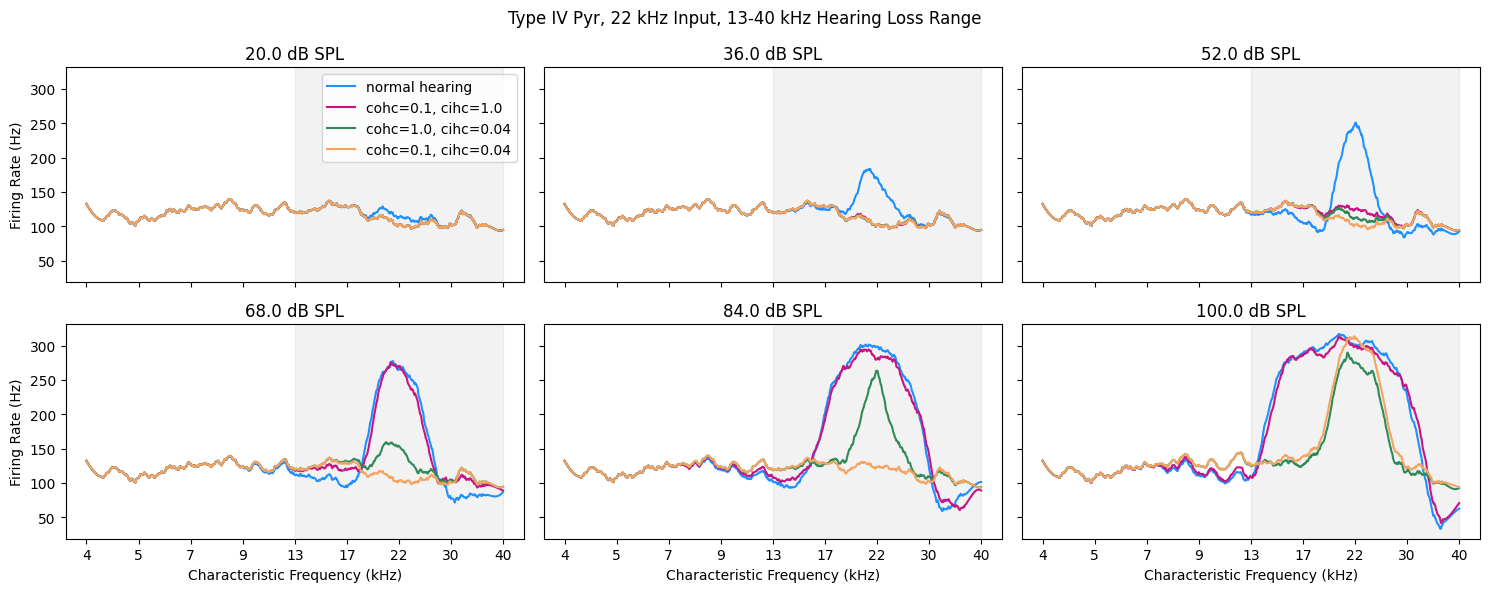

In [35]:
colors = ['tab:blue', 'tab:pink', 'tab:green', 'tab:orange']
colors = ['dodgerblue', 'mediumvioletred', 'seagreen', 'sandybrown']

include_levels = [20, 36, 52, 68, 84, 100]

n_rows = 2
n_cols = 3

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

i = 0

for _, stim_rates in enumerate(zip(stim_avg_rates.items(), stim_avg_rates_loss1.items(), stim_avg_rates_loss2.items(), stim_avg_rates_loss3.items())):
    
    level = stim_rates[0][0].opts['dbspl']

    if level in include_levels:

        window = 50
        axs[i].plot(freqs_log, savgol_filter(stim_rates[0][1], window, 3), color=colors[0], label='normal hearing')
        axs[i].plot(freqs_log, savgol_filter(stim_rates[1][1], window, 3), color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
        axs[i].plot(freqs_log, savgol_filter(stim_rates[2][1], window, 3), color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
        axs[i].plot(freqs_log, savgol_filter(stim_rates[3][1], window, 3), color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')

        # axs[i].plot(freqs_log, stim_rates[0][1], color=colors[0], label='normal hearing')
        # axs[i].plot(freqs_log, stim_rates[1][1], color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
        # axs[i].plot(freqs_log, stim_rates[2][1], color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
        # axs[i].plot(freqs_log, stim_rates[3][1], color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')
        axs[i].set_xticks([freqs_log[i] for i in [0, 83, 166, 249, 332, 415, 498, 581, 664]])
        axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 83, 166, 249, 332, 415, 498, 581, 664]])
        axs[i].axvspan(freqs_log[332], freqs_log[-1], color='grey', alpha=0.1, zorder=1)
        axs[i].set_title(f'{level} dB SPL')
        if i%n_cols == 0:
            axs[i].set_ylabel('Firing Rate (Hz)')
        if i >= n_cols*(n_rows-1):
            axs[i].set_xlabel('Characteristic Frequency (kHz)')

        i += 1

# axs[i].set_xlim(left=20000)
# axs[0].set_ylim([40,310])

axs[0].legend(loc='upper right')  #, bbox_to_anchor=(3, 1))
# fig.set_dpi(300)
# fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.suptitle('Type IV Pyr, 22 kHz Input, 13-40 kHz Hearing Loss Range')
fig.tight_layout()
fig.savefig('typeIV_pyramidal_array-firing_rates.png', dpi=300)
fig.savefig('typeIV_pyramidal_array-firing_rates.pdf', dpi=300)

## 22kHz input, 35kHz loss

### Normal Hearing

In [89]:
stim_avg_rates = pickle.load(open('/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band = pickle.load(open('/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs = list(pyramidal_ids_per_band.keys())
b = (freqs[-1] - freqs[0]) / np.log(freqs[-1] / freqs[0])
a = freqs[0] - b * np.log(freqs[0])
freqs_log = a + b * np.log(freqs)

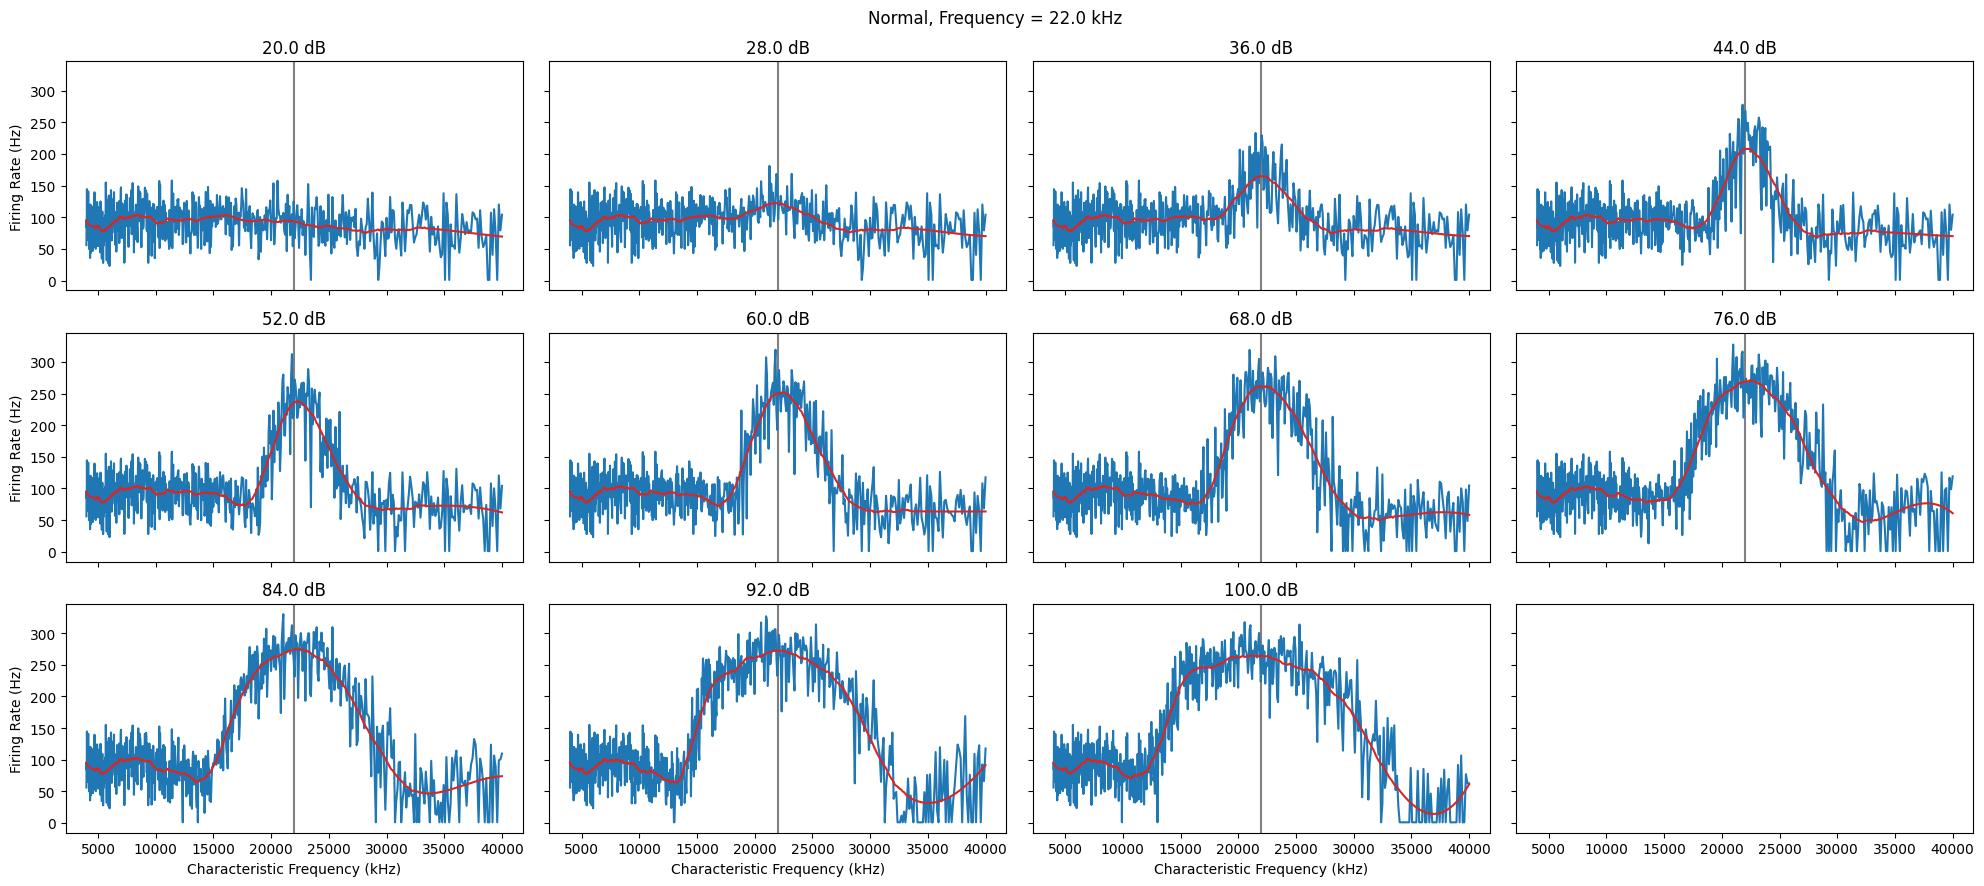

In [90]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Normal, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

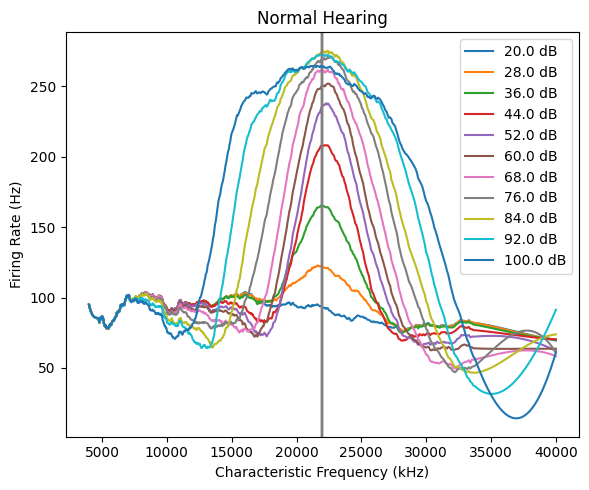

In [91]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title('Normal Hearing')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig('pyramidal_array_firing_rates-normal.png', dpi=300)

### Hearing Loss

#### C_OHC = 0.1, C_IHC = 1.0

In [92]:
cohc1 = 0.1
cihc1 = 1.0

stim_avg_rates_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss1 = list(pyramidal_ids_per_band_loss1.keys())
b = (freqs_loss1[-1] - freqs_loss1[0]) / np.log(freqs_loss1[-1] / freqs_loss1[0])
a = freqs_loss1[0] - b * np.log(freqs_loss1[0])
freqs_log_loss1 = a + b * np.log(freqs_loss1)

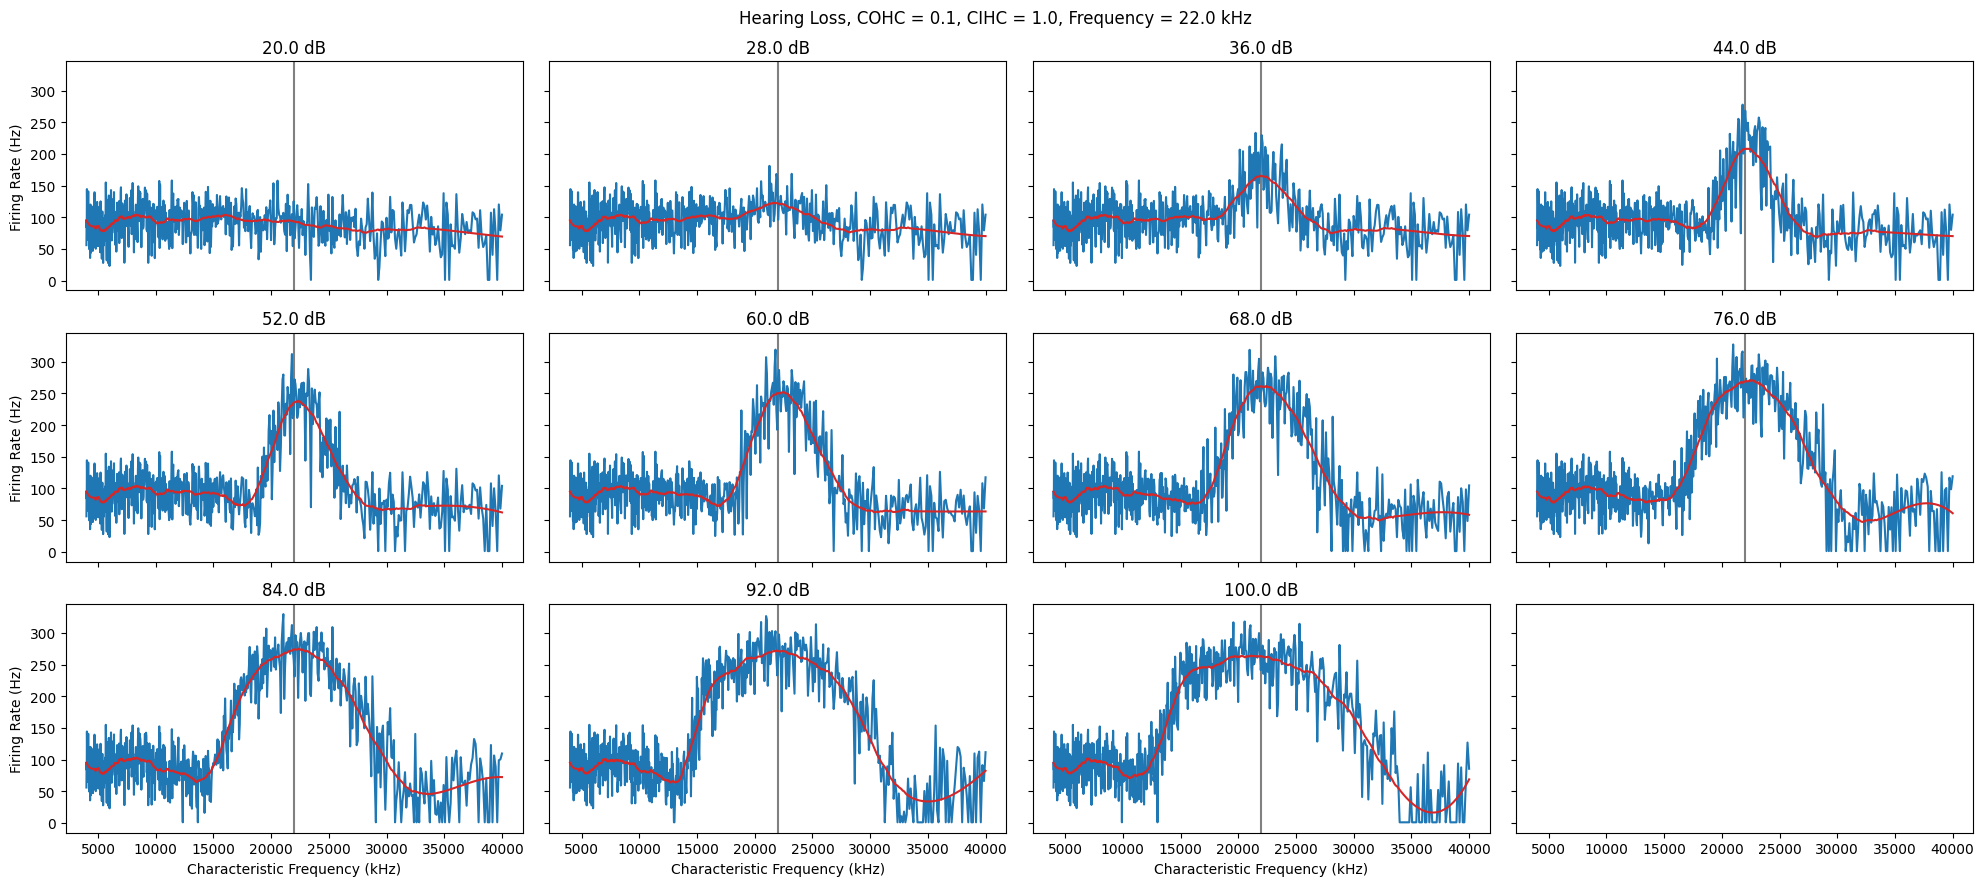

In [93]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss1)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates_loss1.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Hearing Loss, COHC = {cohc1}, CIHC = {cihc1}, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

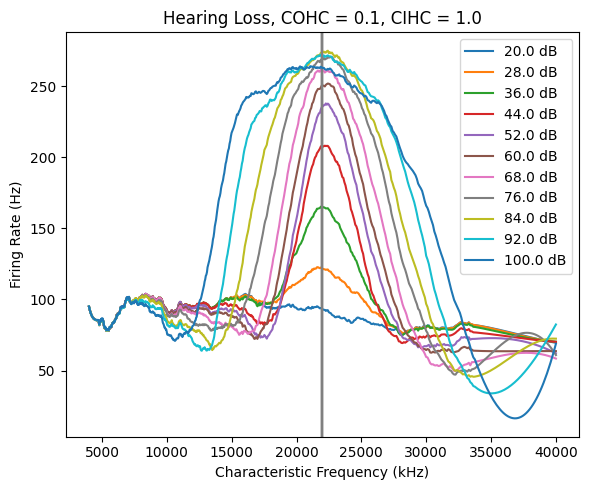

In [94]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates_loss1.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title(f'Hearing Loss, COHC = {cohc1}, CIHC = {cihc1}')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig(f'pyramidal_array_firing_rates-loss-cohc_{cohc1}-cihc{cihc1}.png', dpi=300)

#### COHC = 1.0, CIHC = 0.04

In [95]:
cohc2 = 1.0
cihc2 = 0.04

stim_avg_rates_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss2 = list(pyramidal_ids_per_band_loss2.keys())
b = (freqs_loss2[-1] - freqs_loss2[0]) / np.log(freqs_loss2[-1] / freqs_loss2[0])
a = freqs_loss2[0] - b * np.log(freqs_loss2[0])
freqs_log_loss2 = a + b * np.log(freqs_loss2)

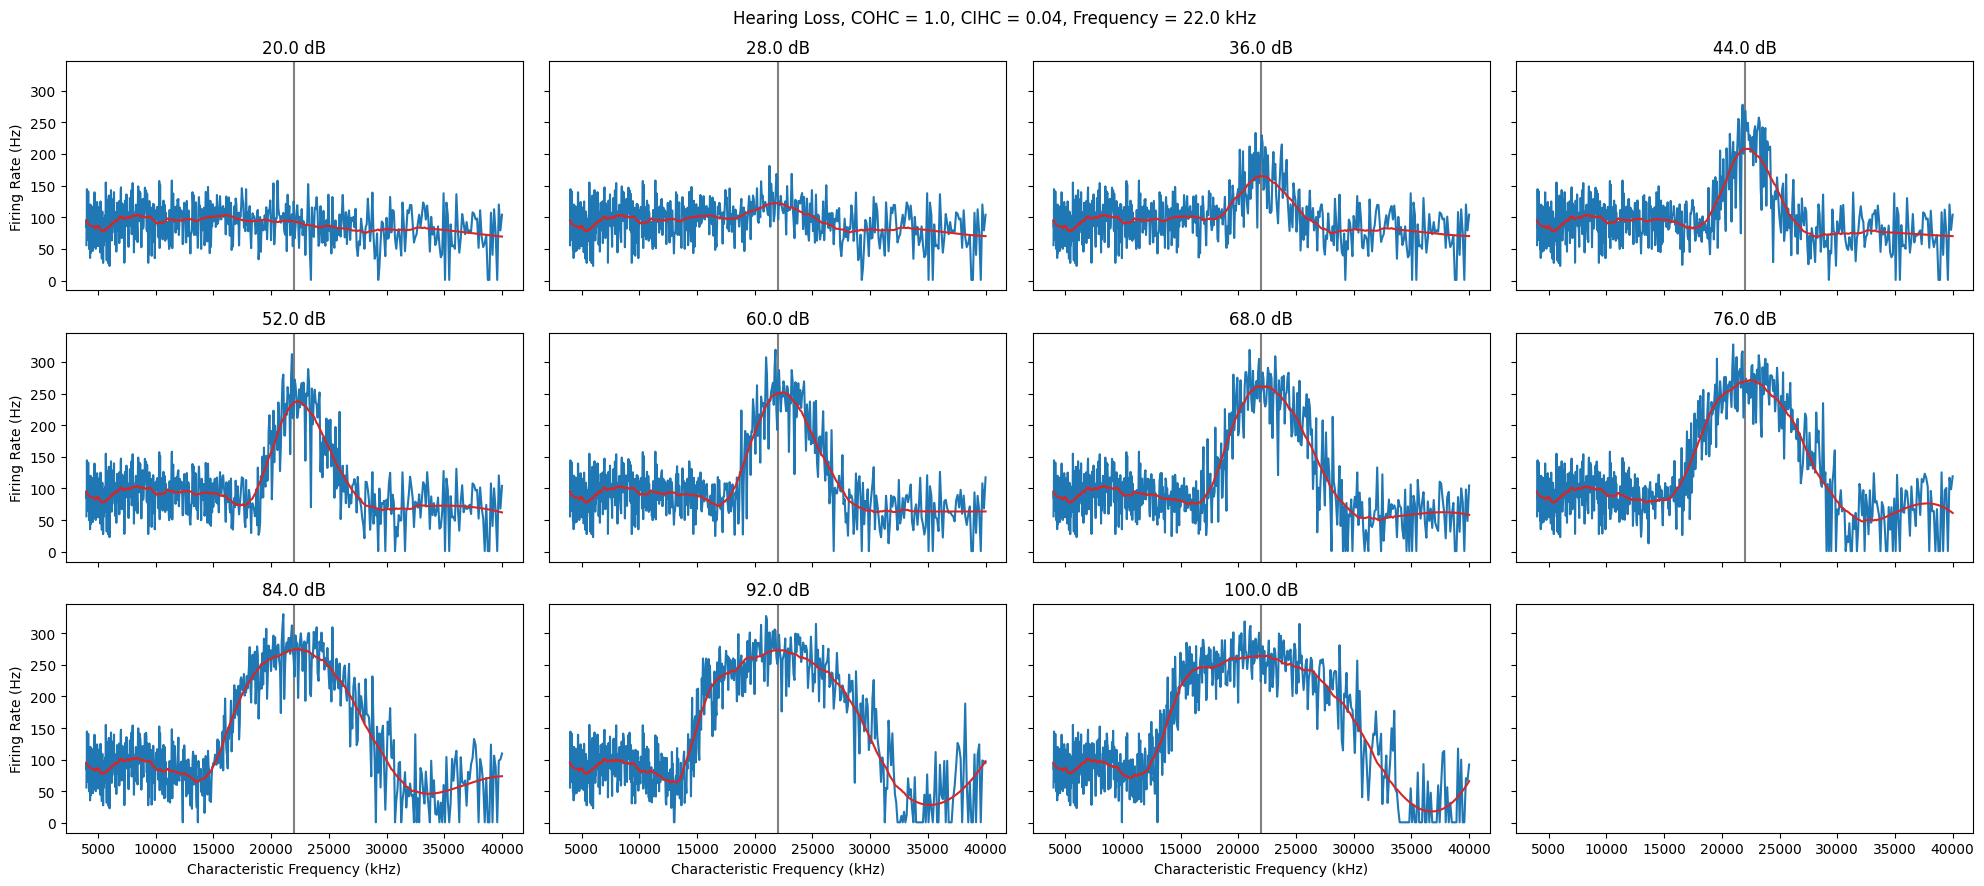

In [96]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss2)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates_loss2.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Hearing Loss, COHC = {cohc2}, CIHC = {cihc2}, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

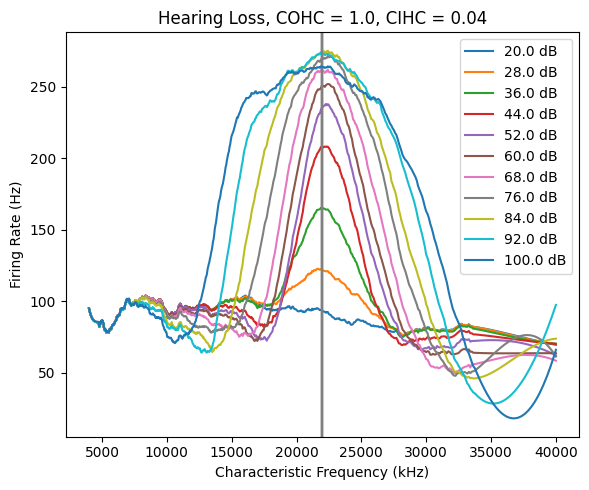

In [97]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates_loss2.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title(f'Hearing Loss, COHC = {cohc2}, CIHC = {cihc2}')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig(f'pyramidal_array_firing_rates-loss-cohc_{cohc2}-cihc{cihc2}.png', dpi=300)

#### COHC = 0.1, CIHC = 0.04

In [98]:
cohc3 = 0.1
cihc3 = 0.04

stim_avg_rates_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss3 = list(pyramidal_ids_per_band_loss3.keys())
b = (freqs_loss3[-1] - freqs_loss3[0]) / np.log(freqs_loss3[-1] / freqs_loss3[0])
a = freqs_loss3[0] - b * np.log(freqs_loss3[0])
freqs_log_loss3 = a + b * np.log(freqs_loss3)

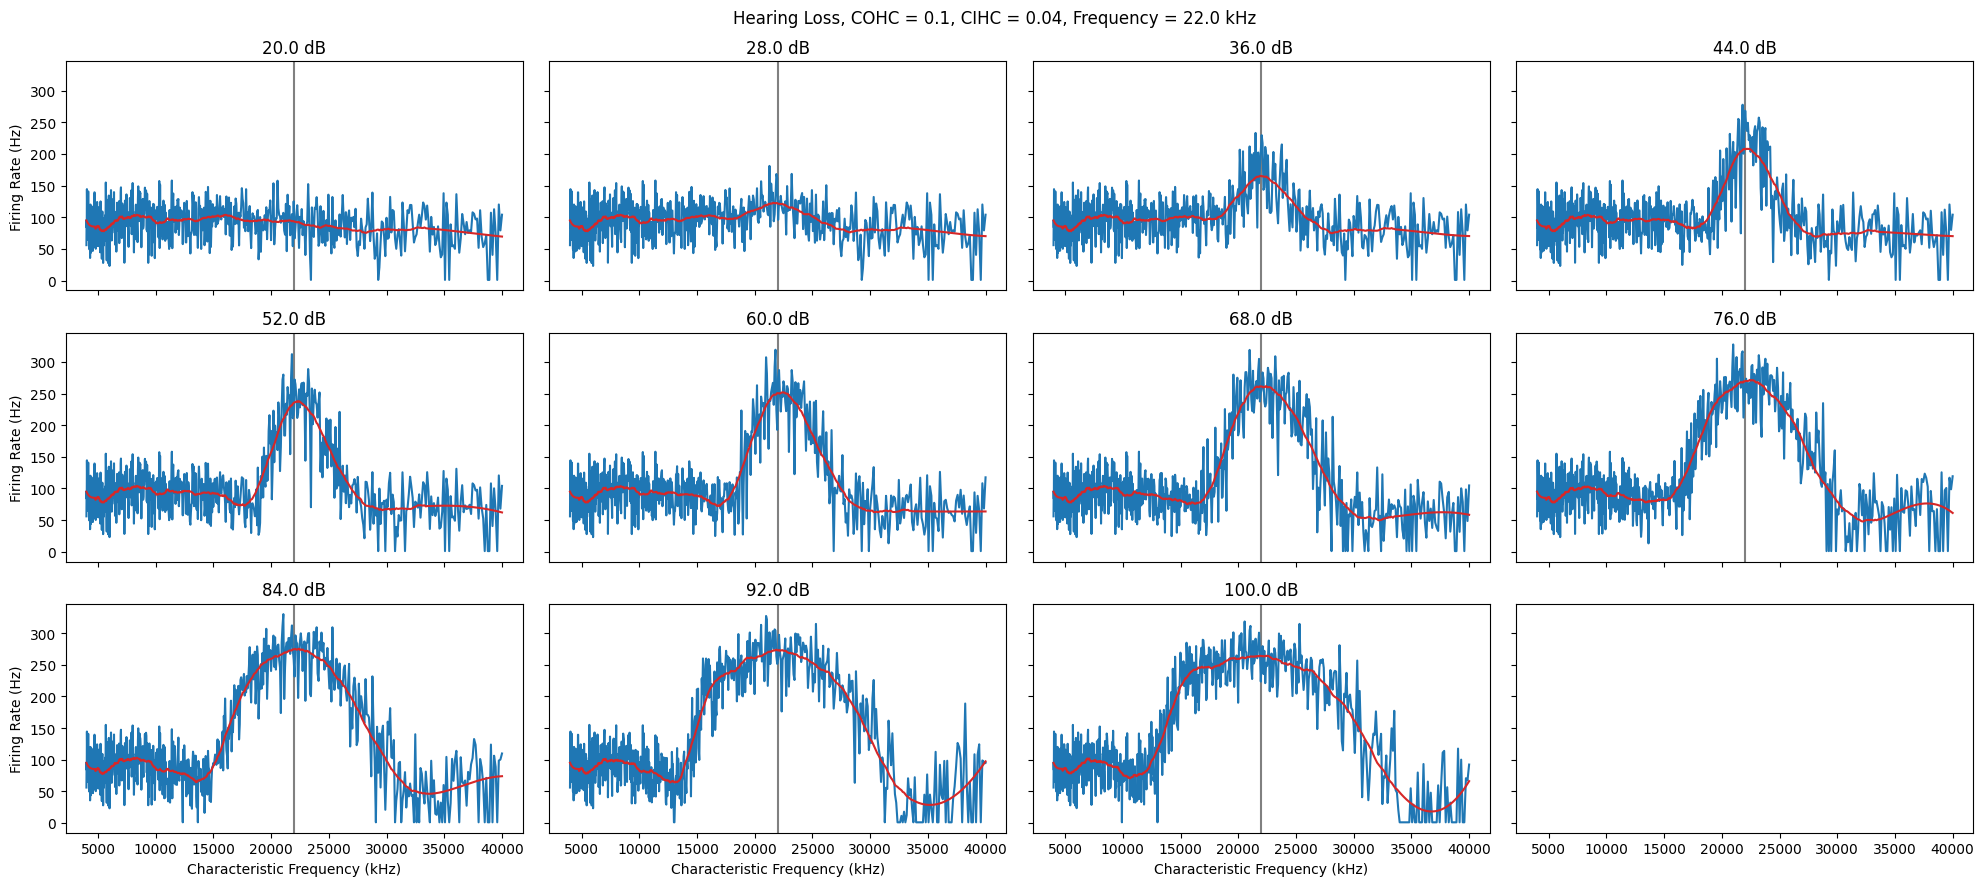

In [99]:
n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss3)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, (stim, avg_rates) in enumerate(stim_avg_rates_loss3.items()):
    level = stim.opts['dbspl']

    axs[i].plot(freqs, avg_rates, color='tab:blue', zorder=12)  #, 'o-')
    axs[i].plot(freqs, savgol_filter(avg_rates, 100, 3), color='tab:red', zorder=13)
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')
# axs[0].set_ylim([40,310])
# fig.set_dpi(300)
fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.tight_layout()

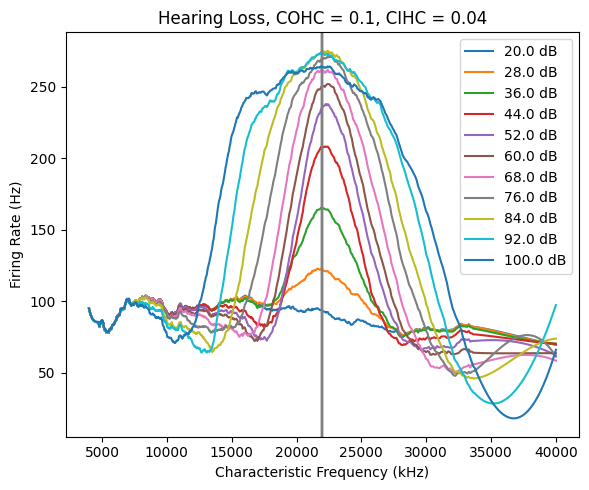

In [100]:
fig, axs = plt.subplots(1,1,figsize=(6,5))

for stim, avg_rates in stim_avg_rates_loss3.items():
    level = stim.opts['dbspl']

    # axs.plot(freqs_log, avg_rates, color='tab:blue')  #, 'o-')
    axs.axvline(input_frequency, color='grey')
    axs.plot(freqs, savgol_filter(avg_rates, 100, 3), label=f'{level} dB')  #, color='tab:red')

# axs.set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
# axs.set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
axs.legend(loc='upper right')
axs.set_xlabel('Characteristic Frequency (kHz)')
axs.set_ylabel('Firing Rate (Hz)')
axs.set_title(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}')
# fig.suptitle(f'Frequency = 10 kHz')
fig.tight_layout()
fig.savefig(f'pyramidal_array_firing_rates-loss-cohc_{cohc3}-cihc{cihc3}.png', dpi=300)


### All

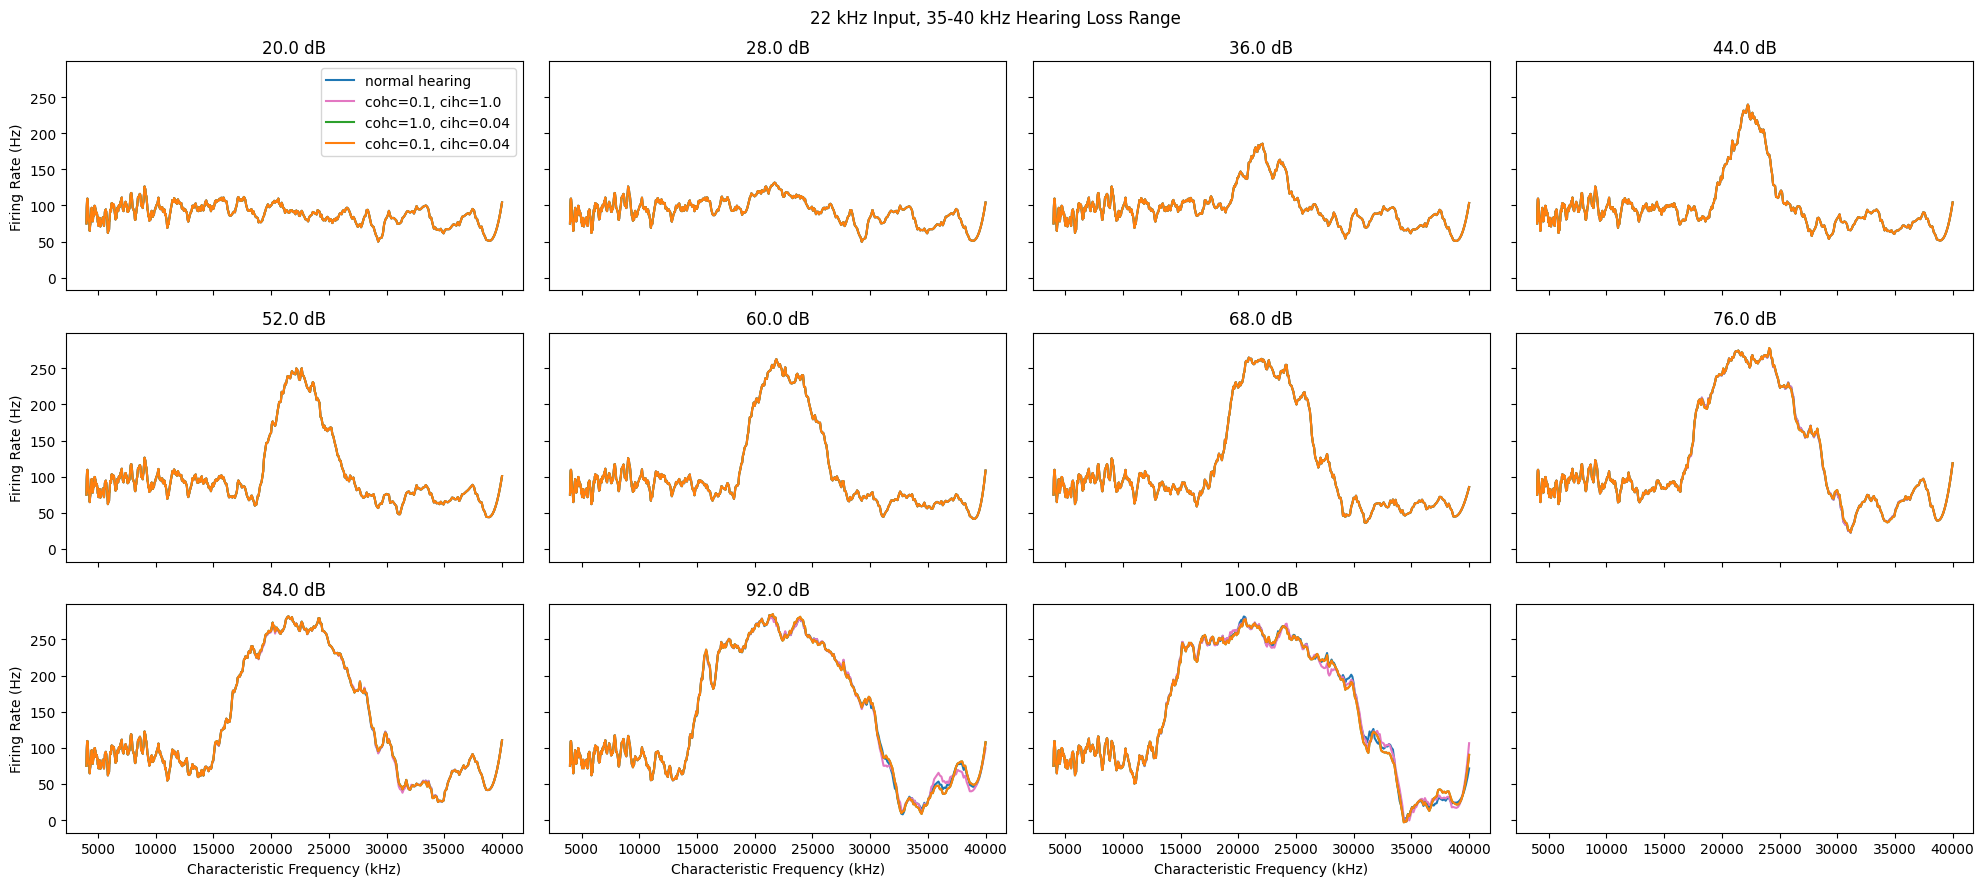

In [104]:
colors = ['tab:blue', 'tab:pink', 'tab:green', 'tab:orange']

n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss3)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, stim_rates in enumerate(zip(stim_avg_rates.items(), stim_avg_rates_loss1.items(), stim_avg_rates_loss2.items(), stim_avg_rates_loss3.items())):
    
    level = stim_rates[0][0].opts['dbspl']

    window = 20
    axs[i].plot(freqs, savgol_filter(stim_rates[0][1], window, 3), color=colors[0], label='normal hearing')
    axs[i].plot(freqs, savgol_filter(stim_rates[1][1], window, 3), color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    axs[i].plot(freqs, savgol_filter(stim_rates[2][1], window, 3), color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    axs[i].plot(freqs, savgol_filter(stim_rates[3][1], window, 3), color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')

    # axs[i].plot(freqs_log, stim_rates[0][1], color=colors[0], label='normal hearing')
    # axs[i].plot(freqs_log, stim_rates[1][1], color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    # axs[i].plot(freqs_log, stim_rates[2][1], color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    # axs[i].plot(freqs_log, stim_rates[3][1], color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    # axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')

# axs[i].set_xlim(left=20000)
# axs[0].set_ylim([40,310])

axs[0].legend(loc='upper right')  #, bbox_to_anchor=(1, 1))
# fig.set_dpi(300)
# fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.suptitle('22 kHz Input, 35-40 kHz Hearing Loss Range')
fig.tight_layout()

## Type III - 22kHz input, 35kHz loss

### All

In [23]:
syns = '-SPx0.00044_VPx0.0006'

stim_avg_rates = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0{syns}/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_1.0-ihc_1.0{syns}/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs = list(pyramidal_ids_per_band.keys())
b = (freqs[-1] - freqs[0]) / np.log(freqs[-1] / freqs[0])
a = freqs[0] - b * np.log(freqs[0])
freqs_log = a + b * np.log(freqs)

In [24]:
cohc1 = 0.1
cihc1 = 1.0

loss = 35000

stim_avg_rates_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}{syns}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss1 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc1}-ihc_{cihc1}{syns}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss1 = list(pyramidal_ids_per_band_loss1.keys())
b = (freqs_loss1[-1] - freqs_loss1[0]) / np.log(freqs_loss1[-1] / freqs_loss1[0])
a = freqs_loss1[0] - b * np.log(freqs_loss1[0])
freqs_log_loss1 = a + b * np.log(freqs_loss1)

In [25]:
cohc2 = 1.0
cihc2 = 0.04

stim_avg_rates_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}{syns}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss2 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc2}-ihc_{cihc2}{syns}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss2 = list(pyramidal_ids_per_band_loss2.keys())
b = (freqs_loss2[-1] - freqs_loss2[0]) / np.log(freqs_loss2[-1] / freqs_loss2[0])
a = freqs_loss2[0] - b * np.log(freqs_loss2[0])
freqs_log_loss2 = a + b * np.log(freqs_loss2)

In [26]:
cohc3 = 0.1
cihc3 = 0.04

stim_avg_rates_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}{syns}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/stim_avg_rates.pkl', 'rb'))

pyramidal_ids_per_band_loss3 = pickle.load(open(f'/data/scrook/dcnmodel_scratch/output/response_maps-network_resp_map-ohc_{cohc3}-ihc_{cihc3}_35000loss-hc/665cfs_11dbs_22000if_1cpb_1nreps/pyramidal_ids_per_band.pkl', 'rb'))

freqs_loss3 = list(pyramidal_ids_per_band_loss3.keys())
b = (freqs_loss3[-1] - freqs_loss3[0]) / np.log(freqs_loss3[-1] / freqs_loss3[0])
a = freqs_loss3[0] - b * np.log(freqs_loss3[0])
freqs_log_loss3 = a + b * np.log(freqs_loss3)

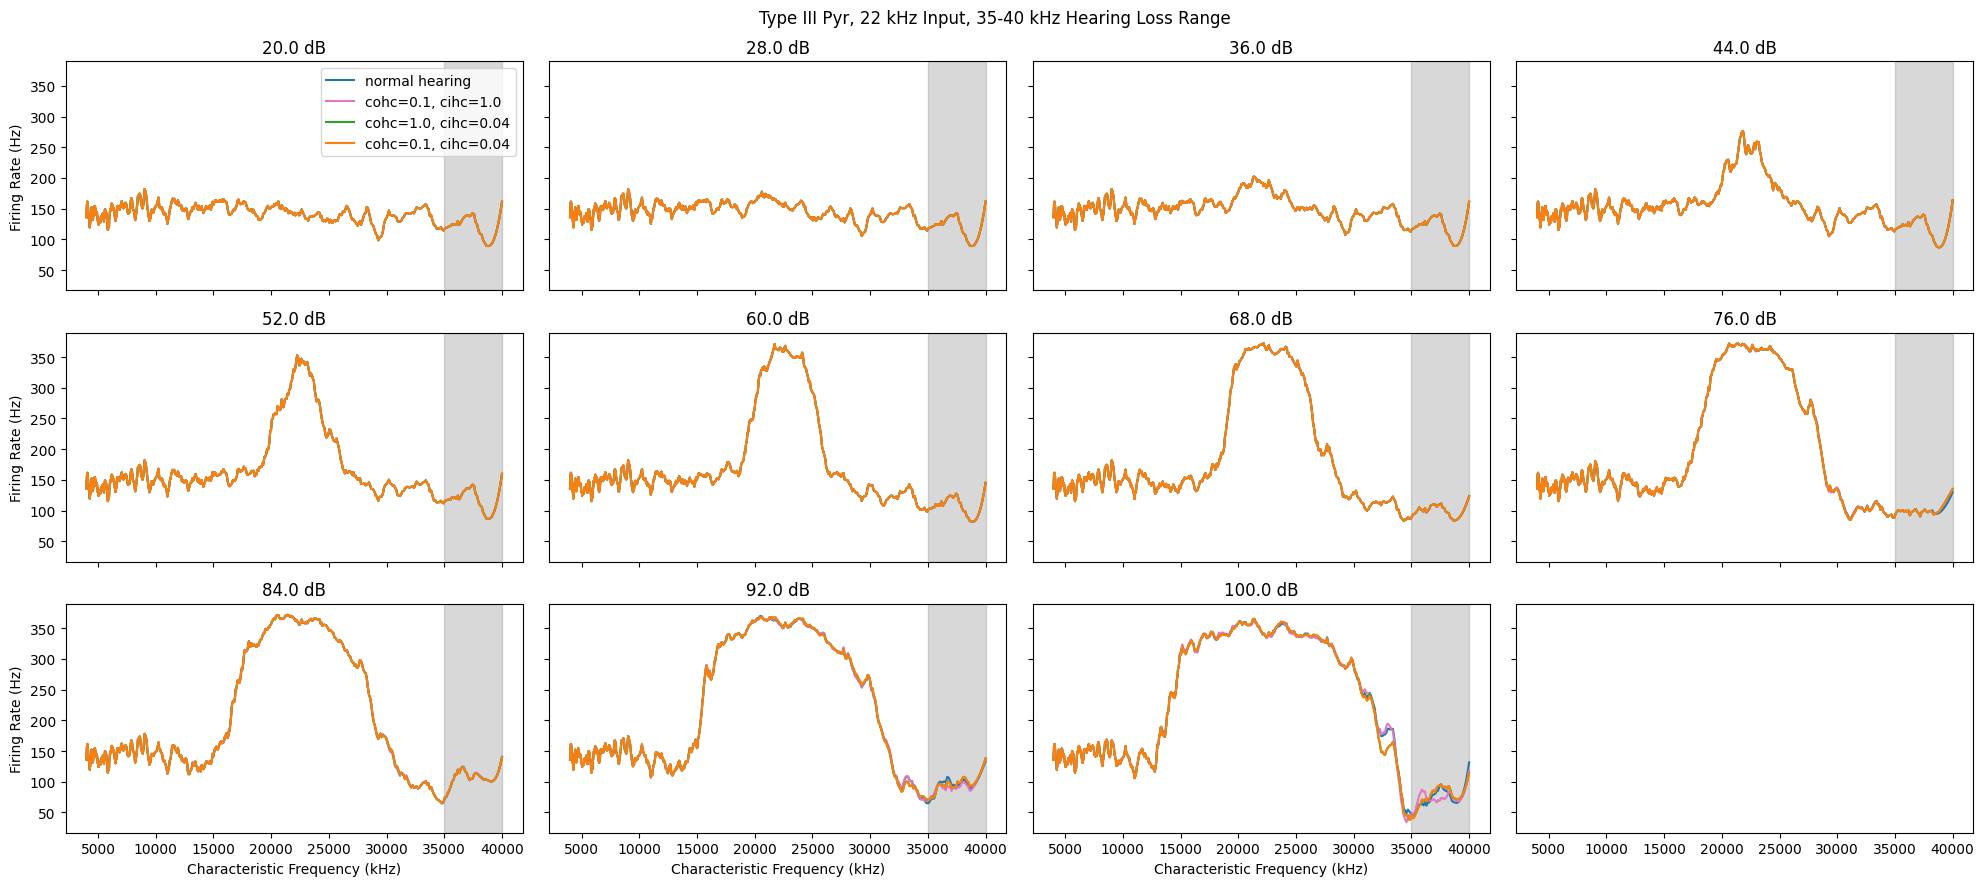

In [27]:
colors = ['tab:blue', 'tab:pink', 'tab:green', 'tab:orange']

n_rows = 3
n_cols = int(np.ceil(len(stim_avg_rates_loss3)/n_rows))

fig, axs = plt.subplots(n_rows,n_cols,figsize=(5*n_cols,3*n_rows), sharey=True, sharex=True)
axs = axs.ravel()

for i, stim_rates in enumerate(zip(stim_avg_rates.items(), stim_avg_rates_loss1.items(), stim_avg_rates_loss2.items(), stim_avg_rates_loss3.items())):
    
    level = stim_rates[0][0].opts['dbspl']

    window = 20
    axs[i].plot(freqs, savgol_filter(stim_rates[0][1], window, 3), color=colors[0], label='normal hearing')
    axs[i].plot(freqs, savgol_filter(stim_rates[1][1], window, 3), color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    axs[i].plot(freqs, savgol_filter(stim_rates[2][1], window, 3), color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    axs[i].plot(freqs, savgol_filter(stim_rates[3][1], window, 3), color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')

    # axs[i].plot(freqs_log, stim_rates[0][1], color=colors[0], label='normal hearing')
    # axs[i].plot(freqs_log, stim_rates[1][1], color=colors[1], label=f'cohc={cohc1}, cihc={cihc1}')
    # axs[i].plot(freqs_log, stim_rates[2][1], color=colors[2], label=f'cohc={cohc2}, cihc={cihc2}')
    # axs[i].plot(freqs_log, stim_rates[3][1], color=colors[3], label=f'cohc={cohc3}, cihc={cihc3}')
    # axs[i].set_xticks([freqs_log[i] for i in [0, 65, 130, 195, 261]])
    # axs[i].set_xticklabels([round(freqs[i]/1000) for i in [0, 65, 130, 195, 261]])
    # axs[i].axvline(input_frequency, color='grey', zorder=1)
    axs[i].axvspan(loss, freqs[-1], color='grey', alpha=0.3, zorder=1)
    axs[i].set_title(f'{level} dB')
    if i%n_cols == 0:
        axs[i].set_ylabel('Firing Rate (Hz)')
    if i >= n_cols*(n_rows-1):
        axs[i].set_xlabel('Characteristic Frequency (kHz)')

# axs[i].set_xlim(left=20000)
# axs[0].set_ylim([40,310])

axs[0].legend(loc='upper right')  #, bbox_to_anchor=(1, 1))
# fig.set_dpi(300)
# fig.suptitle(f'Hearing Loss, COHC = {cohc3}, CIHC = {cihc3}, Frequency = {input_frequency // 1e3} kHz')
fig.suptitle('Type III Pyr, 22 kHz Input, 35-40 kHz Hearing Loss Range')
fig.tight_layout()